# Driven-panel distortion: direct vs side geometry

**Research questions.** Does the same driven panel produce different two-tone interaction products when it serves as the primary reflector versus when a passive panel serves as the reflector and the driven panel is off to the side? How do differences depend on excitation frequency, amplitude, and measured linear paths?

**Input:** `./data/distortion/distortion_direct.npz` and `distortion_side.npz`. The notebook does not modify the input files. All analyses use the stored `error_*`, `ref_*`, frequencies, amplitudes and IRs. Set `DATA_DIR` in the next cell if needed.

**Important interpretation limits:** PSD powers of separately recorded single-source tones are added as a practical *incoherent* baseline. At coincident spectral lines, coherent interference can make both-on power differ even for a linear system. Excess-power values are therefore **not exact nonlinear residuals**. Prefer non-overlapping IMD frequencies, frequency tracking, repeatability, and geometry comparisons. Static IRs describe LTI propagation but cannot fully normalize a time-varying nonlinear scattering process.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

DATA_DIR = Path('./data/distortion')
OUT_DIR = DATA_DIR / 'analysis_outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = {'direct': DATA_DIR / 'distortion_direct.npz', 'side': DATA_DIR / 'distortion_side.npz'}

# Analysis parameters. Change these if recordings/IRs warrant it.
N_PER_SEG = 32768
N_OVERLAP = N_PER_SEG // 2
PEAK_HALF_BINS = 2       # integrate +/- 2 Welch bins around a predicted frequency
HARMONIC_TOL_HZ = 5.0   # minimum harmonic exclusion tolerance; also accounts for bin width
MAX_ORDER = 4           # IMD products with positive integer m,n and m+n <= 4
FREQ_MAX_PLOT = 4000
EPS = 1e-30

def db10(x):
    return 10*np.log10(np.maximum(x, EPS))

def db20(x):
    return 20*np.log10(np.maximum(x, EPS))

## 1. Load and validate the two datasets

Array axes are explicitly defined: `error_both[panel_frequency, source_frequency, panel_amplitude, sample]`, `error_panel[panel_frequency, panel_amplitude, sample]`, and `error_source[source_frequency, sample]`. Reference arrays use the same axes. No silent control is assumed unless explicitly present.

In [3]:
REQUIRED = ['fs','panel_freqs','source_freqs','panel_amps','source_amp',
            'error_panel','error_source','error_both','ref_panel','ref_source','ref_both']

def load_dataset(path):
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. Set DATA_DIR to the folder containing your NPZ files.')
    with np.load(path, allow_pickle=False) as z:
        d = {key: z[key] for key in z.files}
    missing = [key for key in REQUIRED if key not in d]
    if missing: raise KeyError(f'{path.name} missing keys: {missing}')
    d['fs'] = int(np.asarray(d['fs']).item())
    for name in ['panel_freqs','source_freqs','panel_amps']:
        d[name] = np.asarray(d[name]).ravel()
    p,s,a = map(len, (d['panel_freqs'],d['source_freqs'],d['panel_amps']))
    for prefix in ['error','ref']:
        assert d[f'{prefix}_both'].shape[:3] == (p,s,a), (path,prefix,'both shape')
        assert d[f'{prefix}_panel'].shape[:2] == (p,a), (path,prefix,'panel shape')
        assert d[f'{prefix}_source'].shape[0] == s, (path,prefix,'source shape')
        assert len(set([d[f'{prefix}_{k}'].shape[-1] for k in ['both','panel','source']])) == 1, 'Sample counts differ'
    return d

data = {name:load_dataset(path) for name,path in FILES.items()}
for name,d in data.items():
    print(name, 'fs:',d['fs'], 'panel:',d['panel_freqs'], 'source:',d['source_freqs'],
          'amplitudes:',d['panel_amps'])
    print('  shapes:', {k:d[k].shape for k in ['error_both','error_panel','error_source','ref_both']})
    print('  IR shapes:',{k:d[k].shape for k in ['error_ir','ref_ir','error_ir_raw','ref_ir_raw'] if k in d})
for field in ['fs','panel_freqs','source_freqs','panel_amps']:
    assert np.array_equal(data['direct'][field], data['side'][field]), f'Grid mismatch: {field}'
assert np.isclose(float(data['direct']['source_amp']),float(data['side']['source_amp']))
fs = data['direct']['fs']
panel_freqs = data['direct']['panel_freqs']
source_freqs = data['direct']['source_freqs']
panel_amps = data['direct']['panel_amps']

direct fs: 96000 panel: [250 275 300 325 350 375 400 425 450 475 500] source: [ 700  800  900 1000 1100 1200 1300 1400 1500] amplitudes: [0.15 0.25 0.4  0.5 ]
  shapes: {'error_both': (11, 9, 4, 96000), 'error_panel': (11, 4, 96000), 'error_source': (9, 96000), 'ref_both': (11, 9, 4, 96000)}
  IR shapes: {'error_ir': (256,), 'ref_ir': (256,), 'error_ir_raw': (1535999,), 'ref_ir_raw': (1535999,)}
side fs: 96000 panel: [250 275 300 325 350 375 400 425 450 475 500] source: [ 700  800  900 1000 1100 1200 1300 1400 1500] amplitudes: [0.15 0.25 0.4  0.5 ]
  shapes: {'error_both': (11, 9, 4, 96000), 'error_panel': (11, 4, 96000), 'error_source': (9, 96000), 'ref_both': (11, 9, 4, 96000)}
  IR shapes: {'error_ir': (256,), 'ref_ir': (256,), 'error_ir_raw': (1535999,), 'ref_ir_raw': (1535999,)}


## 2. Data-quality checks

Check finite samples, clipping/near-full-scale, RMS levels, and single-source controls. A large source-only level difference between geometries matters because the cardioid microphone and passive reflector affect the primary path. These tests do not assume the recordings are phase synchronized.

,geometry,channel,condition,shape,finite_fraction,max_abs,near_full_scale_fraction,median_recording_rms
0,direct,error,panel,"(11, 4, 96000)",1.0,0.396881,0.0,0.067294
1,direct,error,source,"(9, 96000)",1.0,0.043488,0.0,0.020548
2,direct,error,both,"(11, 9, 4, 96000)",1.0,0.407166,0.0,0.057318
3,direct,ref,panel,"(11, 4, 96000)",1.0,0.018738,0.0,0.004290
4,direct,ref,source,"(9, 96000)",1.0,0.194580,0.0,0.106457
5,direct,ref,both,"(11, 9, 4, 96000)",1.0,0.208282,0.0,0.108993
6,side,error,panel,"(11, 4, 96000)",1.0,0.018616,0.0,0.006870
7,side,error,source,"(9, 96000)",1.0,0.063416,0.0,0.030398
8,side,error,both,"(11, 9, 4, 96000)",1.0,0.077698,0.0,0.030400
9,side,ref,panel,"(11, 4, 96000)",1.0,0.013336,0.0,0.005499


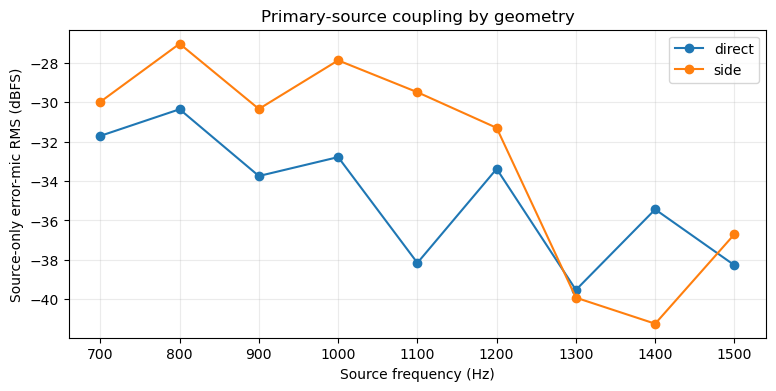

In [3]:
def rms(x):
    x=np.asarray(x,dtype=np.float64)
    return np.sqrt(np.mean(x*x))

quality=[]
for geometry,d in data.items():
    for channel in ['error','ref']:
        for condition in ['panel','source','both']:
            x=d[f'{channel}_{condition}']
            quality.append(dict(geometry=geometry,channel=channel,condition=condition,
                shape=str(x.shape),finite_fraction=float(np.isfinite(x).mean()),
                max_abs=float(np.nanmax(np.abs(x))),
                near_full_scale_fraction=float(np.mean(np.abs(x)>=0.99)),
                median_recording_rms=float(np.median(np.sqrt(np.mean(np.asarray(x,dtype=np.float64)**2,axis=-1))))))
quality_df=pd.DataFrame(quality)
display(quality_df)
quality_df.to_csv(OUT_DIR/'quality.csv',index=False)

fig,ax=plt.subplots(figsize=(9,4))
for geometry,d in data.items():
    levels=np.array([db20(rms(x)) for x in d['error_source']])
    ax.plot(source_freqs,levels,'o-',label=geometry)
ax.set(xlabel='Source frequency (Hz)',ylabel='Source-only error-mic RMS (dBFS)',title='Primary-source coupling by geometry')
ax.legend();ax.grid(alpha=.25);plt.show()

## 3. Impulse-response comparison

Plot **raw** and aligned IRs separately. A raw IR may include acquisition delay; the aligned IR may be shifted/truncated. The `panel_to_err_cm` field documents the alignment parameter but is not necessarily the complete acoustic path geometry. Cumulative IR energy quantifies truncation, *not* whether late energy is physical versus noise.

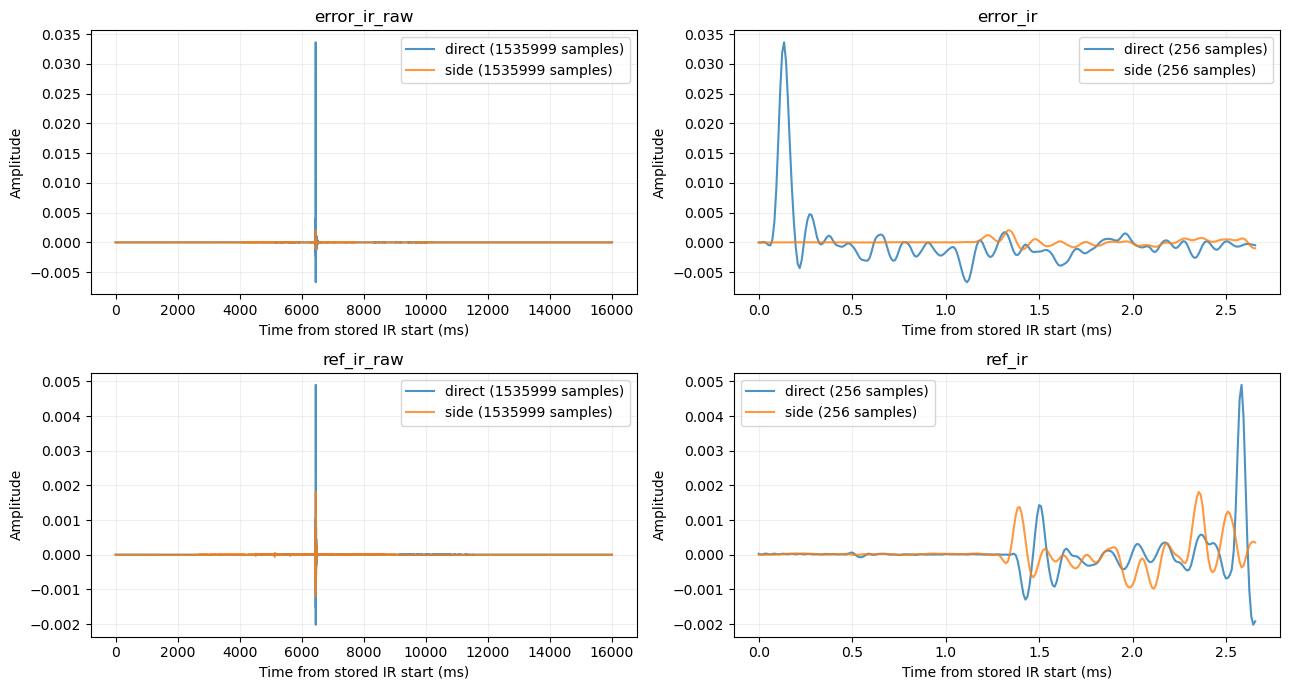

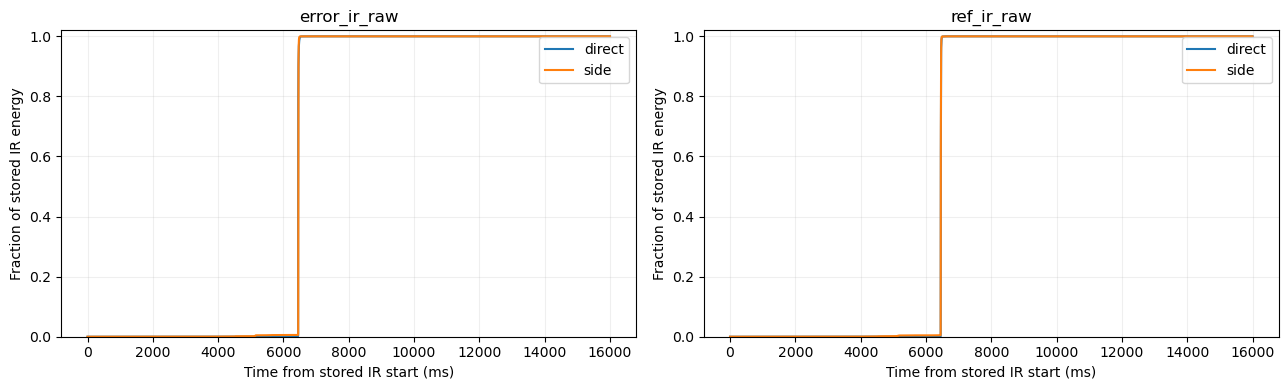

In [4]:
def plot_irs(key):
    fig,axes=plt.subplots(2,2,figsize=(13,7))
    for row,base in enumerate(['error_ir','ref_ir']):
        for col,suffix in enumerate(['_raw','']):
            ax=axes[row,col]; name=base+suffix
            for geom,d in data.items():
                if name not in d: continue
                h=np.asarray(d[name]).squeeze()
                if h.ndim!=1: print('Skipping non-1D IR',geom,name,h.shape);continue
                ax.plot(np.arange(len(h))/fs*1000,h,label=f'{geom} ({len(h)} samples)',alpha=.8)
            ax.set(xlabel='Time from stored IR start (ms)',ylabel='Amplitude',title=name)
            ax.grid(alpha=.2);ax.legend()
    fig.tight_layout();plt.show()
plot_irs('all')

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,base in zip(axes,['error_ir_raw','ref_ir_raw']):
    for geom,d in data.items():
        if base not in d:continue
        h=np.asarray(d[base]).squeeze().astype(float)
        if h.ndim!=1:continue
        cum=np.cumsum(h*h)
        if cum[-1]>0:
            ax.plot(np.arange(1,len(h)+1)/fs*1000,cum/cum[-1],label=geom)
    ax.set(xlabel='Time from stored IR start (ms)',ylabel='Fraction of stored IR energy',title=base,ylim=(0,1.02))
    ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.show()

## 4. Spectrum utilities and a measured-vs-predicted example

Welch PSDs are integrated over a small bin neighborhood to reduce sensitivity to leakage and small frequency offsets. This is **band power**, not a single-bin peak. The sum-of-powers baseline is not valid as a coherent waveform prediction where components overlap; see overlap flags below.

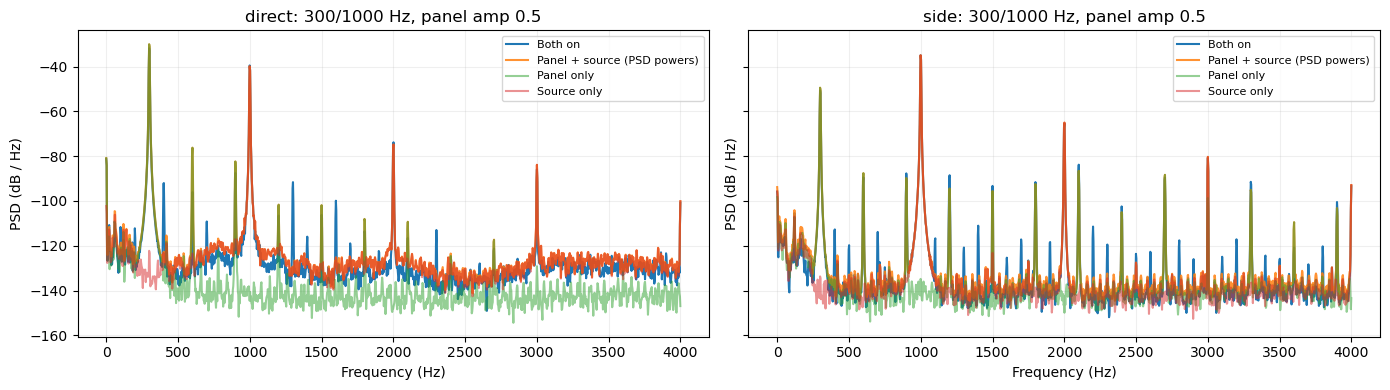

In [5]:
def psd(x,fs=fs):
    x=np.asarray(x,dtype=np.float64)
    nperseg=min(N_PER_SEG,len(x))
    f,p=signal.welch(x,fs=fs,window='hann',nperseg=nperseg,
                     noverlap=min(N_OVERLAP,nperseg-1),detrend='constant',scaling='density')
    return f,p

def band_power(f,p,center,half_bins=PEAK_HALF_BINS):
    if center < 0 or center > f[-1]:return np.nan
    df=f[1]-f[0]
    idx=np.argmin(np.abs(f-center))
    lo=max(0,idx-half_bins);hi=min(len(f),idx+half_bins+1)
    return float(np.sum(p[lo:hi])*df)

def get_triple(d,channel,i,j,k):
    return (d[f'{channel}_both'][i,j,k],
            d[f'{channel}_panel'][i,k],
            d[f'{channel}_source'][j])

def spectrum_triple(d,channel,i,j,k):
    both,panel,source=get_triple(d,channel,i,j,k)
    f,pb=psd(both);_,pp=psd(panel);_,ps=psd(source)
    return f,pb,pp,ps

def idx_exact(arr,value):
    idx=np.flatnonzero(np.isclose(arr,value))
    if not len(idx):raise ValueError(f'{value} not in {arr}')
    return int(idx[0])

P_EXAMPLE=300;S_EXAMPLE=1000;A_EXAMPLE=0.5
pi=idx_exact(panel_freqs,P_EXAMPLE);sj=idx_exact(source_freqs,S_EXAMPLE);ak=idx_exact(panel_amps,A_EXAMPLE)
fig,axes=plt.subplots(1,2,figsize=(14,4),sharey=True)
for ax,(geom,d) in zip(axes,data.items()):
    f,pb,pp,ps=spectrum_triple(d,'error',pi,sj,ak)
    m=f<=FREQ_MAX_PLOT
    ax.plot(f[m],db10(pb[m]),label='Both on')
    ax.plot(f[m],db10((pp+ps)[m]),label='Panel + source (PSD powers)',alpha=.85)
    ax.plot(f[m],db10(pp[m]),label='Panel only',alpha=.5)
    ax.plot(f[m],db10(ps[m]),label='Source only',alpha=.5)
    ax.set(xlabel='Frequency (Hz)',ylabel='PSD (dB / Hz)',title=f'{geom}: {P_EXAMPLE}/{S_EXAMPLE} Hz, panel amp {A_EXAMPLE}')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()

## 5. Generate all IMD candidates and flag harmonic overlap

Candidate frequencies are \( |m f_p \pm n f_s| \), with \(m,n\ge 1\) and \(m+n\le\) `MAX_ORDER`. A candidate is marked **ambiguous** if it lies near a harmonic of either excitation, near DC, or another degenerate product. Such rows remain in the exported table but should not be used as primary evidence for interaction. Welch resolution is incorporated into the overlap tolerance.

In [6]:
def imd_candidates(fp,fsrc,nyquist=fs/2):
    out=[]
    for m in range(1,MAX_ORDER):
        for n in range(1,MAX_ORDER):
            if m+n>MAX_ORDER:continue
            for sign in (-1,1):
                freq=abs(m*fp+sign*n*fsrc)
                if freq<=0 or freq>=nyquist:continue
                out.append(dict(freq=float(freq),m=m,n=n,sign=sign,
                                label=f'{m}P {"+" if sign>0 else "-"} {n}S',order=m+n))
    return out

def is_harmonic_overlap(freq,fp,fsrc,tol):
    for base in (fp,fsrc):
        if base<=0:continue
        nearest=round(freq/base)
        if nearest>=1 and abs(freq-nearest*base)<=tol:return True
    return False

def classify_candidates(fp,fsrc):
    candidates=imd_candidates(fp,fsrc)
    tol=max(HARMONIC_TOL_HZ,2*fs/min(N_PER_SEG,fs))
    for item in candidates:
        item['harmonic_overlap']=is_harmonic_overlap(item['freq'],fp,fsrc,tol)
        item['near_dc']=item['freq']<=tol
        item['duplicate_product']=sum(abs(other['freq']-item['freq'])<=tol for other in candidates)>1
        item['clean']=not (item['harmonic_overlap'] or item['near_dc'] or item['duplicate_product'])
    return candidates

print(pd.DataFrame(classify_candidates(300,1000)).to_string(index=False))

  freq  m  n  sign   label  order  harmonic_overlap  near_dc  duplicate_product  clean
 700.0  1  1    -1 1P - 1S      2             False    False              False   True
1300.0  1  1     1 1P + 1S      2             False    False              False   True
1700.0  1  2    -1 1P - 2S      3             False    False              False   True
2300.0  1  2     1 1P + 2S      3             False    False              False   True
2700.0  1  3    -1 1P - 3S      4              True    False              False  False
3300.0  1  3     1 1P + 3S      4              True    False              False  False
 400.0  2  1    -1 2P - 1S      3             False    False              False   True
1600.0  2  1     1 2P + 1S      3             False    False              False   True
1400.0  2  2    -1 2P - 2S      4             False    False              False   True
2600.0  2  2     1 2P + 2S      4             False    False              False   True
 100.0  3  1    -1 3P - 1S      4          

## 6. Full-grid IMD extraction (error and reference microphones)

For each candidate band, calculate:
- `both_dBc`: both-on component relative to the **source-only fundamental power at that microphone**;
- `positive_excess_dBc`: positive part of `both − (panel + source)` band power, relative to source fundamental;
- `excess_ratio_dB`: `both / (panel + source)` in dB;
- `clearance_dB`: component prominence above a nearby local PSD baseline (approximate);
- `clean`: harmonic/degeneracy screening.

These are screening statistics, not proof of a particular physical nonlinear mechanism.

In [7]:
def local_clearance(f,p,freq,exclusion_hz=20,outer_hz=75):
    mask=(np.abs(f-freq)>=exclusion_hz)&(np.abs(f-freq)<=outer_hz)
    if not mask.any():return np.nan
    target=band_power(f,p,freq)
    baseline=float(np.median(p[mask]))*(2*PEAK_HALF_BINS+1)*(f[1]-f[0])
    return float(db10(target/baseline))

rows=[]
for geom,d in data.items():
    for channel in ['error','ref']:
        for i,fp in enumerate(panel_freqs):
            for j,fsrc in enumerate(source_freqs):
                candidates=classify_candidates(float(fp),float(fsrc))
                for k,amp in enumerate(panel_amps):
                    f,pb,pp,ps=spectrum_triple(d,channel,i,j,k)
                    fund=band_power(f,ps,float(fsrc))
                    for item in candidates:
                        freq=item['freq']
                        measured=band_power(f,pb,freq)
                        predicted=band_power(f,pp+ps,freq)
                        positive=max(0.,measured-predicted)
                        rows.append(dict(geometry=geom,channel=channel,
                            panel_freq=float(fp),source_freq=float(fsrc),panel_amp=float(amp),
                            source_amp=float(d['source_amp']),**item,
                            both_power=measured,predicted_power=predicted,
                            source_fundamental_power=fund,
                            both_dBc=float(db10(measured/fund)),
                            positive_excess_dBc=float(db10(positive/fund)) if positive>0 else np.nan,
                            excess_ratio_dB=float(db10(measured/predicted)),
                            clearance_dB=local_clearance(f,pb,freq)))
imd=pd.DataFrame(rows)
imd.to_csv(OUT_DIR/'imd_all_candidates.csv',index=False)
print(f'{len(imd):,} candidate rows; {imd.clean.sum():,} marked clean')
display(imd[(imd.geometry=='direct')&(imd.channel=='error')&
            (imd.panel_freq==300)&(imd.source_freq==1000)&
            (imd.panel_amp==A_EXAMPLE)].sort_values('both_dBc',ascending=False).head(15))

18,896 candidate rows; 15,680 marked clean


,geometry,channel,panel_freq,source_freq,panel_amp,source_amp,freq,m,n,sign,...,near_dc,duplicate_product,clean,both_power,predicted_power,source_fundamental_power,both_dBc,positive_excess_dBc,excess_ratio_dB,clearance_dB
1046,direct,error,300.0,1000.0,0.5,1.0,400.0,2,1,-1,...,False,False,True,3.716718e-09,5.501405e-12,0.000527,-51.519177,-51.525610,28.296860,28.963082
1041,direct,error,300.0,1000.0,0.5,1.0,1300.0,1,1,1,...,False,False,True,3.340217e-09,1.242443e-12,0.000527,-51.983025,-51.984641,34.294984,35.297255
1047,direct,error,300.0,1000.0,0.5,1.0,1600.0,2,1,1,...,False,False,True,4.606250e-10,3.025814e-12,0.000527,-60.587298,-60.615921,21.825053,29.648914
1040,direct,error,300.0,1000.0,0.5,1.0,700.0,1,1,-1,...,False,False,True,5.572102e-11,8.809041e-12,0.000527,-69.760582,-70.507935,8.010904,11.915998
1050,direct,error,300.0,1000.0,0.5,1.0,100.0,3,1,-1,...,False,False,True,3.681478e-11,1.377809e-11,0.000527,-71.560551,-73.596573,4.268330,7.175665
1043,direct,error,300.0,1000.0,0.5,1.0,2300.0,1,2,1,...,False,False,True,2.325498e-11,6.904830e-13,0.000527,-73.555614,-73.686517,15.273629,18.448063
1048,direct,error,300.0,1000.0,0.5,1.0,1400.0,2,2,-1,...,False,False,True,1.276271e-11,3.065803e-12,0.000527,-76.161345,-77.354442,6.193985,11.997686
1042,direct,error,300.0,1000.0,0.5,1.0,1700.0,1,2,-1,...,False,False,True,6.552855e-12,3.528542e-12,0.000527,-79.056467,-82.414504,2.688353,10.123346
1044,direct,error,300.0,1000.0,0.5,1.0,2700.0,1,3,-1,...,False,False,False,4.512249e-12,1.090257e-11,0.000527,-80.676842,NaN,-3.831358,9.887758
1051,direct,error,300.0,1000.0,0.5,1.0,1900.0,3,1,1,...,False,False,True,4.011658e-12,1.750403e-12,0.000527,-81.187534,-83.677278,3.601858,6.186663


## 7. Direct-versus-side paired comparisons

Compare **the same predicted product** at the same input settings. Differences in `both_dBc` are normalized to the source fundamental *within each geometry*, but this does not fully correct different propagation paths or local incident pressure on the driven panel. Compare `positive_excess_dBc` and `excess_ratio_dB` alongside it. Use only clean candidates with adequate prominence when drawing conclusions.

In [8]:
keys=['channel','panel_freq','source_freq','panel_amp','freq','m','n','sign','label','order']
metrics=['both_dBc','positive_excess_dBc','excess_ratio_dB','clearance_dB','source_fundamental_power']
direct=imd[imd.geometry=='direct'][keys+metrics+['clean']].rename(columns={c:c+'_direct' for c in metrics})
side=imd[imd.geometry=='side'][keys+metrics].rename(columns={c:c+'_side' for c in metrics})
comparison=direct.merge(side,on=keys,validate='one_to_one')
for metric in ['both_dBc','positive_excess_dBc','excess_ratio_dB']:
    comparison[metric+'_direct_minus_side']=comparison[metric+'_direct']-comparison[metric+'_side']
comparison.to_csv(OUT_DIR/'imd_geometry_comparison.csv',index=False)
filtered=comparison[(comparison.channel=='error')&comparison.clean&
                    (comparison.clearance_dB_direct>=10)&
                    (comparison.clearance_dB_side>=10)]
print('Clean, prominent paired products:',len(filtered))
display(filtered.sort_values('both_dBc_direct_minus_side',ascending=False)
        [['panel_freq','source_freq','panel_amp','freq','label',
          'both_dBc_direct','both_dBc_side','both_dBc_direct_minus_side',
          'excess_ratio_dB_direct','excess_ratio_dB_side']].head(25))

Clean, prominent paired products: 506


,panel_freq,source_freq,panel_amp,freq,label,both_dBc_direct,both_dBc_side,both_dBc_direct_minus_side,excess_ratio_dB_direct,excess_ratio_dB_side
140,250.0,900.0,0.50,1300.0,2P - 2S,-34.999416,-82.925864,47.926447,48.233778,16.350751
128,250.0,900.0,0.40,1300.0,2P - 2S,-35.994784,-80.986122,44.991339,47.187050,16.269652
1094,300.0,1100.0,0.50,500.0,2P - 1S,-38.996316,-80.418748,41.422432,41.274602,13.494932
954,300.0,800.0,0.50,200.0,2P - 1S,-39.351961,-77.081110,37.729150,41.318227,4.375808
1835,350.0,900.0,0.25,1600.0,2P + 1S,-45.458091,-83.073347,37.615256,7.169221,-15.184570
6,250.0,700.0,0.15,200.0,2P - 1S,12.576571,-24.622614,37.199185,-0.790689,-1.444277
42,250.0,700.0,0.50,200.0,2P - 1S,19.752692,-17.211917,36.964609,-0.675200,-0.998464
30,250.0,700.0,0.40,200.0,2P - 1S,18.920325,-17.898512,36.818838,-0.724884,-1.032578
18,250.0,700.0,0.25,200.0,2P - 1S,16.171853,-20.601470,36.773323,-0.728250,-1.167772
1077,300.0,1100.0,0.40,1400.0,1P + 1S,-42.403325,-79.096510,36.693186,36.654107,16.315144


## 8. Heatmaps across the frequency grid

Choose a metric and an amplitude. The **strongest clean candidate** per grid point is convenient for screening, but a max over many candidates is subject to selection bias; the next section tracks individual product families more rigorously. Cells with no clean candidate are left blank.

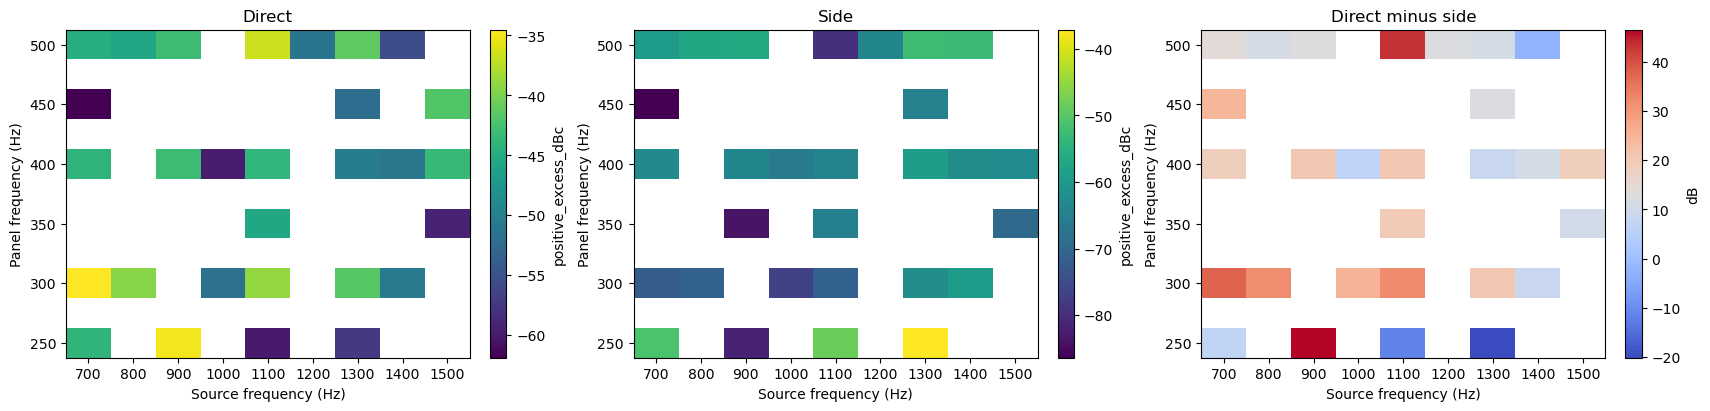

In [9]:
HEATMAP_AMP=0.5
HEATMAP_METRIC='positive_excess_dBc' # also: 'both_dBc', 'excess_ratio_dB'

def heatmap_grid(geometry,metric=HEATMAP_METRIC,amp=HEATMAP_AMP,channel='error'):
    sub=imd[(imd.geometry==geometry)&(imd.channel==channel)&imd.clean&
            np.isclose(imd.panel_amp,amp)]
    sub=sub[sub.clearance_dB>=10]
    agg=sub.groupby(['panel_freq','source_freq'])[metric].max()
    return agg.reindex(pd.MultiIndex.from_product([panel_freqs,source_freqs])).to_numpy().reshape(len(panel_freqs),len(source_freqs))

a=heatmap_grid('direct');b=heatmap_grid('side')
fig,axes=plt.subplots(1,3,figsize=(17,4),constrained_layout=True)
for ax,z,title in zip(axes,[a,b,a-b],['Direct','Side','Direct minus side']):
    cmap='coolwarm' if 'minus' in title else 'viridis'
    im=ax.imshow(z,origin='lower',aspect='auto',cmap=cmap,
                 extent=[source_freqs[0]-50,source_freqs[-1]+50,panel_freqs[0]-12.5,panel_freqs[-1]+12.5])
    ax.set(xlabel='Source frequency (Hz)',ylabel='Panel frequency (Hz)',title=title)
    fig.colorbar(im,ax=ax,label='dB' if 'minus' in title else HEATMAP_METRIC)
plt.show()

## 9. Track specific product families instead of only maxima

Plot \(f_s\pm f_p\) and \(|f_s-2f_p|\) separately. A product can be harmonically overlapped at some grid points; those points are masked. This avoids conflating changes in which product happens to be largest.

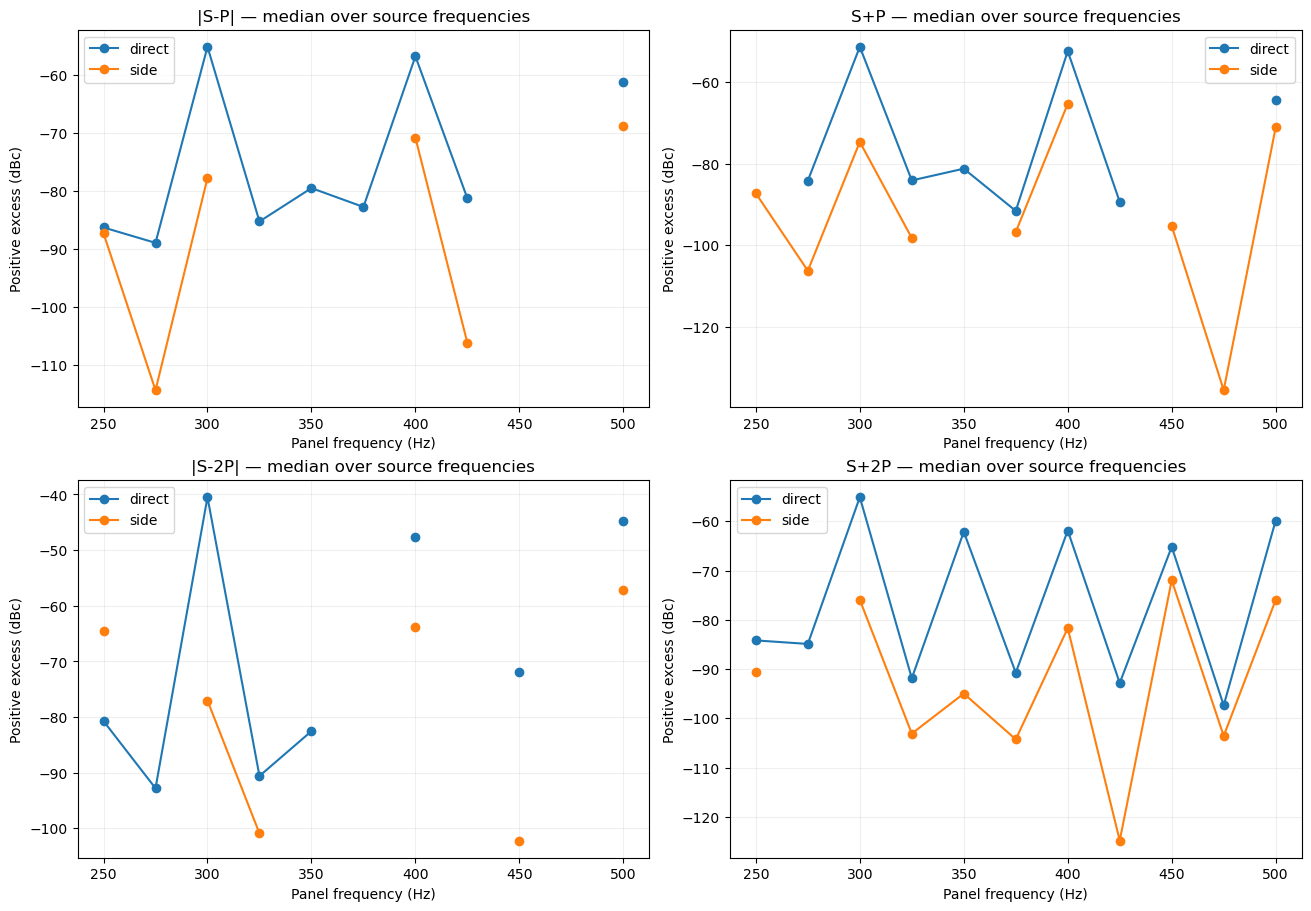

In [10]:
FAMILIES=[(1,1,-1,'|S-P|'),(1,1,1,'S+P'),(2,1,-1,'|S-2P|'),(2,1,1,'S+2P')]
FAMILY_AMP=0.5
fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for ax,(m,n,sign,label) in zip(axes.ravel(),FAMILIES):
    for geom in ['direct','side']:
        sub=imd[(imd.geometry==geom)&(imd.channel=='error')&imd.clean&
                (imd.m==m)&(imd.n==n)&(imd.sign==sign)&
                np.isclose(imd.panel_amp,FAMILY_AMP)]
        vals=sub.groupby('panel_freq')['positive_excess_dBc'].median()
        ax.plot(vals.index,vals.values,'o-',label=geom)
    ax.set(title=f'{label} — median over source frequencies',xlabel='Panel frequency (Hz)',
           ylabel='Positive excess (dBc)')
    ax.grid(alpha=.2);ax.legend()
plt.show()

## 10. Amplitude dependence: fit slopes in dB/dB

For a power-law interaction amplitude \(A_\mathrm{IMD}\propto A_p^q\), the level in dB changes by \(q\) times the panel-drive level change in dB. Here we fit *positive excess band power*, so the slope is only meaningful when the excess is reliably above the baseline at multiple amplitudes. Avoid using `both_dBc` as a nonlinear-order estimate when the band has substantial ordinary single-source power.

,geometry,panel_freq,source_freq,freq,m,n,sign,label,n_levels,slope_db_per_db,correlation
262,side,500.0,1300.0,3100.0,1,2,1,1P + 2S,3,0.920401,0.999996
50,direct,400.0,900.0,500.0,1,1,-1,1P - 1S,3,0.886797,0.999994
67,direct,400.0,1300.0,2200.0,1,2,-1,1P - 2S,3,0.891140,0.999992
122,direct,500.0,1300.0,1800.0,1,1,1,1P + 1S,3,0.983298,0.999990
174,side,300.0,1400.0,2500.0,1,2,-1,1P - 2S,3,0.805855,0.999961
3,direct,250.0,1100.0,1700.0,2,2,-1,2P - 2S,3,0.919955,0.999949
198,side,400.0,1100.0,300.0,2,1,-1,2P - 1S,3,2.222042,0.999893
44,direct,400.0,700.0,1100.0,1,1,1,1P + 1S,3,1.364282,0.999839
112,direct,500.0,1100.0,2700.0,1,2,1,1P + 2S,4,0.928369,0.999829
27,direct,300.0,1100.0,1900.0,1,2,-1,1P - 2S,4,0.824500,0.999720


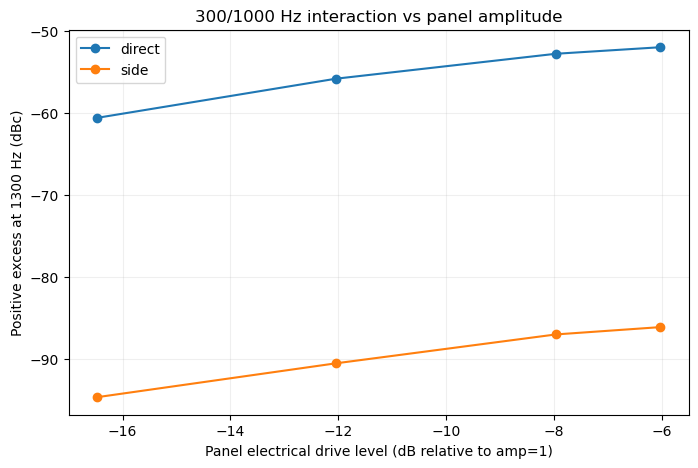

In [11]:
slope_rows=[]
for keys_group,g in imd[(imd.channel=='error')&imd.clean].groupby(
        ['geometry','panel_freq','source_freq','freq','m','n','sign','label']):
    good=g[(g.clearance_dB>=10)&np.isfinite(g.positive_excess_dBc)]
    if len(good)<3:continue
    x=db20(good.panel_amp.to_numpy(dtype=float))
    y=good.positive_excess_dBc.to_numpy(dtype=float)
    slope,intercept=np.polyfit(x,y,1)
    r=np.corrcoef(x,y)[0,1] if np.std(y)>0 else np.nan
    slope_rows.append(dict(zip(['geometry','panel_freq','source_freq','freq','m','n','sign','label'],keys_group),
                           n_levels=len(good),slope_db_per_db=slope,correlation=r))
slopes=pd.DataFrame(slope_rows)
slopes.to_csv(OUT_DIR/'amplitude_slopes.csv',index=False)
if len(slopes):
    display(slopes.sort_values('correlation',ascending=False).head(20))
else:
    print('No candidates with >=3 detectable amplitude levels; inspect clearance thresholds.')

# Detailed example: 300 Hz panel, 1000 Hz source, S+P = 1300 Hz
fig,ax=plt.subplots(figsize=(8,5))
for geom in ['direct','side']:
    sub=imd[(imd.geometry==geom)&(imd.channel=='error')&
        (imd.panel_freq==300)&(imd.source_freq==1000)&
        (imd.m==1)&(imd.n==1)&(imd.sign==1)].sort_values('panel_amp')
    if len(sub):ax.plot(db20(sub.panel_amp),sub.positive_excess_dBc,'o-',label=geom)
ax.set(xlabel='Panel electrical drive level (dB relative to amp=1)',
       ylabel='Positive excess at 1300 Hz (dBc)',title='300/1000 Hz interaction vs panel amplitude')
ax.grid(alpha=.2);ax.legend();plt.show()

## 11. Broadband additivity summary

A complementary screening metric integrates positive excess PSD across a band after masking neighborhoods of all harmonics of the input tones. **Caution:** PSD subtraction with clipping to zero has a positive bias even for noisy linear systems; this is descriptive, not a calibrated nonlinear power estimator. Spectral windows and the chosen mask matter.

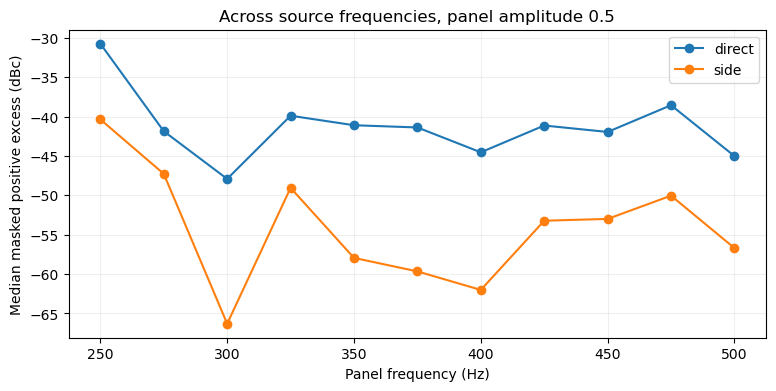

In [12]:
BAND=(50,4000)
MASK_HZ=12
summary=[]
for geom,d in data.items():
    for i,fp in enumerate(panel_freqs):
        for j,fsrc in enumerate(source_freqs):
            for k,amp in enumerate(panel_amps):
                f,pb,pp,ps=spectrum_triple(d,'error',i,j,k)
                keep=(f>=BAND[0])&(f<=BAND[1])
                for base in [fp,fsrc]:
                    if base<=0:continue
                    for h in np.arange(1,int(BAND[1]//base)+2):
                        keep &= np.abs(f-h*base)>MASK_HZ
                excess=np.maximum(pb-pp-ps,0)
                df=f[1]-f[0]
                source_fund=band_power(f,ps,float(fsrc))
                summary.append(dict(geometry=geom,panel_freq=float(fp),source_freq=float(fsrc),
                                    panel_amp=float(amp),masked_excess_power=float(np.sum(excess[keep])*df),
                                    masked_excess_dBc=float(db10(np.sum(excess[keep])*df/source_fund)),
                                    n_bins=int(keep.sum())))
summary_df=pd.DataFrame(summary)
summary_df.to_csv(OUT_DIR/'broadband_excess_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
for geom,g in summary_df.groupby('geometry'):
    ax.plot(panel_freqs,[g[np.isclose(g.panel_freq,p)&np.isclose(g.panel_amp,A_EXAMPLE)].masked_excess_dBc.median()
                         for p in panel_freqs],'o-',label=geom)
ax.set(xlabel='Panel frequency (Hz)',ylabel='Median masked positive excess (dBc)',
       title=f'Across source frequencies, panel amplitude {A_EXAMPLE}')
ax.grid(alpha=.2);ax.legend();plt.show()

## 12. Reference microphone: does the same mixing appear upstream?

The reference mic is not an electrical loopback, so IMD detected there does **not** prove electrical contamination. But comparing error and reference levels may help localize where mixing is strongest. Also inspect the panel-only signal on the reference mic for acoustic feedback.

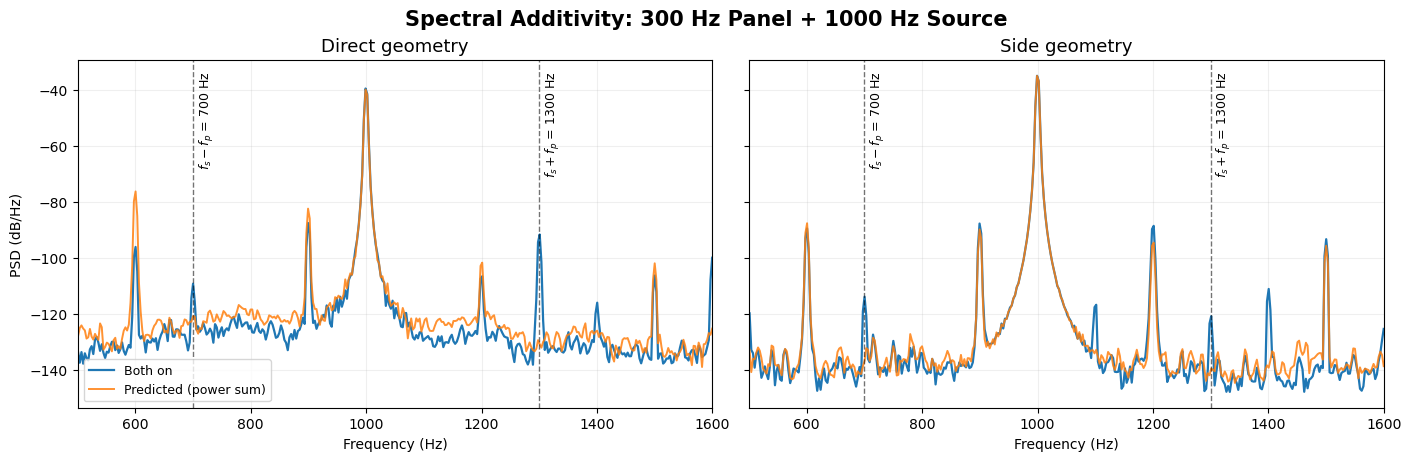

In [28]:

# Example: panel = 300 Hz, source = 1000 Hz
# IMD products: 700 Hz (difference), 1300 Hz (sum)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 4.5),
    sharex=True, sharey=True,
    constrained_layout=True
)

imd_lines = [
    (700,  r"$f_s - f_p$ = 700 Hz"),
    (1300, r"$f_s + f_p$ = 1300 Hz"),
]

for ax, (geom, d) in zip(axes, data.items()):
    f, p_both, p_panel, p_source = spectrum_triple(
        d, "error", pi, sj, ak
    )

    mask = (f >= 500) & (f <= 1600)

    ax.plot(
        f[mask], db10(p_both[mask]),
        label="Both on",
        linewidth=1.6
    )
    ax.plot(
        f[mask], db10((p_panel + p_source)[mask]),
        label="Predicted (power sum)",
        linewidth=1.4,
        alpha=0.85
    )

    # Mark second-order IMD frequencies
    for freq, label in imd_lines:
        ax.axvline(
            freq, color="black",
            linestyle="--", linewidth=1,
            alpha=0.55
        )
        ax.text(
            freq + 8, 0.97, label,
            transform=ax.get_xaxis_transform(),
            rotation=90,
            va="top", ha="left",
            fontsize=9
        )

    ax.set_title(f"{geom.capitalize()} geometry", fontsize=13)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(500, 1600)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("PSD (dB/Hz)")
axes[0].legend(loc="lower left", fontsize=9)

fig.suptitle(
    "Spectral Additivity: 300 Hz Panel + 1000 Hz Source",
    fontsize=15,
    fontweight="bold"
)

plt.show()


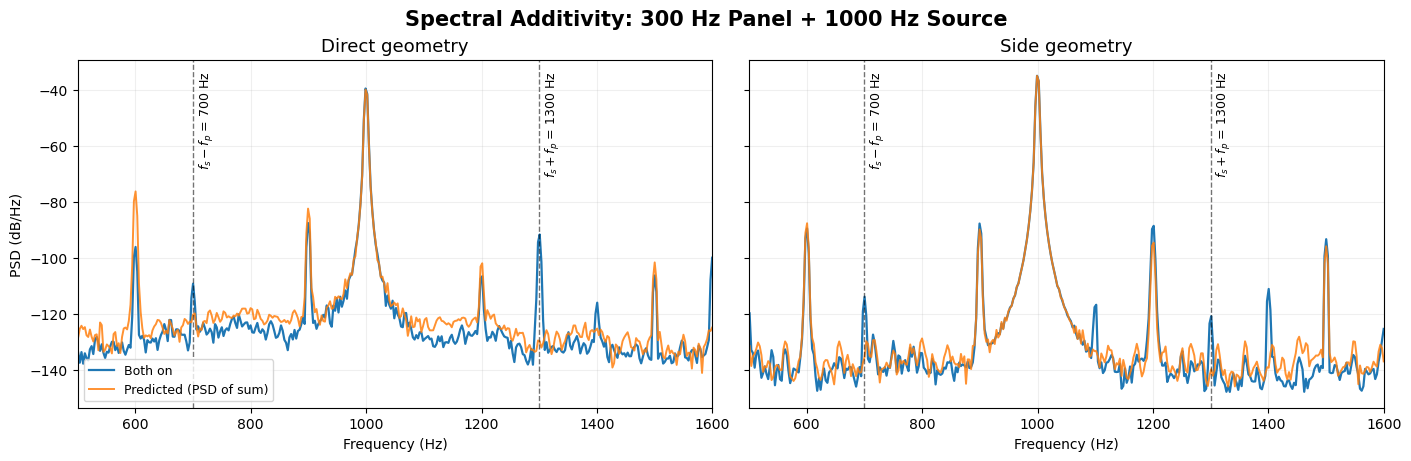

In [31]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4.5),
    sharex=True, sharey=True,
    constrained_layout=True
)

imd_lines = [
    (700,  r"$f_s - f_p$ = 700 Hz"),
    (1300, r"$f_s + f_p$ = 1300 Hz"),
]

for ax, (geom, d) in zip(axes, data.items()):

    # Individual recordings
    panel = d["error_panel"][pi, ak]
    source = d["error_source"][sj]
    both = d["error_both"][pi, sj, ak]

    # Time-domain sum of individual recordings
    predicted = panel + source

    # Compute PSDs
    f, p_both = psd(both)
    _, p_predicted = psd(predicted)

    mask = (f >= 500) & (f <= 1600)

    ax.plot(
        f[mask], db10(p_both[mask]),
        label="Both on",
        linewidth=1.6
    )
    ax.plot(
        f[mask], db10(p_predicted[mask]),
        label="Predicted (PSD of sum)",
        linewidth=1.4,
        alpha=0.85
    )

    for freq, label in imd_lines:
        ax.axvline(
            freq,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.55
        )
        ax.text(
            freq + 8, 0.97, label,
            transform=ax.get_xaxis_transform(),
            rotation=90,
            va="top", ha="left",
            fontsize=9
        )

    ax.set_title(f"{geom.capitalize()} geometry", fontsize=13)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(500, 1600)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("PSD (dB/Hz)")
axes[0].legend(loc="lower left", fontsize=9)

fig.suptitle(
    "Spectral Additivity: 300 Hz Panel + 1000 Hz Source",
    fontsize=15,
    fontweight="bold"
)

plt.show()


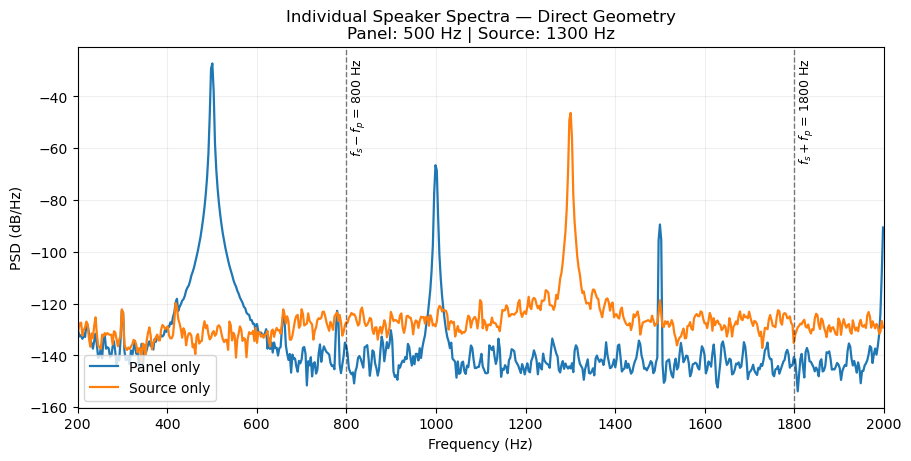

In [46]:

geom = "direct"  # "direct" or "side"
d = data[geom]

f, p_both, p_panel, p_source = spectrum_triple(
    d, "error", pi, sj, ak
)

mask = (f >= 200) & (f <= 2000)

fig, ax = plt.subplots(
    figsize=(9, 4.5),
    constrained_layout=True
)

ax.plot(
    f[mask], db10(p_panel[mask]),
    label="Panel only",
    linewidth=1.6
)

ax.plot(
    f[mask], db10(p_source[mask]),
    label="Source only",
    linewidth=1.6
)

# Mark predicted second-order IMD frequencies
fp = float(d["panel_freqs"][pi])
fsrc = float(d["source_freqs"][sj])

for freq, label in [
    (abs(fsrc - fp), r"$f_s-f_p$"),
    (fsrc + fp, r"$f_s+f_p$")
]:
    ax.axvline(
        freq,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.5
    )
    ax.text(
        freq + 8, 0.97,
        f"{label} = {freq:g} Hz",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        va="top",
        fontsize=9
    )

ax.set(
    title=f"Individual Speaker Spectra — {geom.capitalize()} Geometry\n"
          f"Panel: {fp:g} Hz | Source: {fsrc:g} Hz",
    xlabel="Frequency (Hz)",
    ylabel="PSD (dB/Hz)",
    xlim=(200, 2000)
)

ax.grid(alpha=0.2)
ax.legend(loc="lower left")

plt.show()


In [18]:

from scipy.signal import welch


def plot_spectra(
    data,
    panel_freq=300,
    source_freq=1000,
    panel_amp=0.5,
    geom="direct",
    show_source=False,
    show_panel=False,
    show_sum=True,
    show_dual=True,
    sum_mode="waveform",  # "waveform" or "power"
    freq_min=200,
    freq_max=2000,
    error_mic=True,
    show_fundamentals=False,
    show_imd=True,
    show_title=True,
    figsize=(9, 3.6),
    nperseg=16384
):
    d = data[geom]

    # ==========================================
    # Select experimental conditions
    # ==========================================
    panel_freqs = np.asarray(d["panel_freqs"], dtype=float)
    source_freqs = np.asarray(d["source_freqs"], dtype=float)
    panel_amps = np.asarray(d["panel_amps"], dtype=float)

    pi = int(np.argmin(abs(panel_freqs - panel_freq)))
    sj = int(np.argmin(abs(source_freqs - source_freq)))
    ak = int(np.argmin(abs(panel_amps - panel_amp)))

    fp = panel_freqs[pi]
    fsrc = source_freqs[sj]
    amp = panel_amps[ak]

    for name, requested, actual, available in [
        ("Panel frequency", panel_freq, fp, panel_freqs),
        ("Source frequency", source_freq, fsrc, source_freqs),
        ("Panel amplitude", panel_amp, amp, panel_amps)
    ]:
        if not np.isclose(requested, actual):
            raise ValueError(
                f"{name} {requested} not found. Available: {available}"
            )

    if sum_mode not in ("waveform", "power"):
        raise ValueError("sum_mode must be 'waveform' or 'power'")

    mic = "error" if error_mic else "ref"
    fs = float(d["fs"])

    # ==========================================
    # Load recordings
    # ==========================================
    x_panel = np.asarray(
        d[f"{mic}_panel"][pi, ak], dtype=np.float64
    )
    x_source = np.asarray(
        d[f"{mic}_source"][sj], dtype=np.float64
    )
    x_both = np.asarray(
        d[f"{mic}_both"][pi, sj, ak], dtype=np.float64
    )

    N = min(len(x_panel), len(x_source), len(x_both))

    x_panel = x_panel[:N]
    x_source = x_source[:N]
    x_both = x_both[:N]

    # ==========================================
    # Calculate PSDs
    # ==========================================
    n = min(nperseg, N)

    def get_psd(x):
        return welch(
            x,
            fs=fs,
            nperseg=n,
            noverlap=n // 2,
            window="hann",
            scaling="density"
        )

    f, p_panel = get_psd(x_panel)
    _, p_source = get_psd(x_source)
    _, p_both = get_psd(x_both)

    if sum_mode == "waveform":
        _, p_sum = get_psd(x_panel + x_source)
        sum_label = "Linear sum"
    else:
        p_sum = p_panel + p_source
        sum_label = "Power sum"

    mask = (f >= freq_min) & (f <= freq_max)

    def to_db(x):
        return 10 * np.log10(np.maximum(x, 1e-30))

    # ==========================================
    # Figure
    # ==========================================
    fig, ax = plt.subplots(
        figsize=figsize,
        constrained_layout=True
    )

    # Individual recordings
    if show_source:
        ax.plot(
            f[mask], to_db(p_source[mask]),
            label="Source only",
            color="tab:green",
            linewidth=1.4,
            alpha=0.85
        )

    if show_panel:
        ax.plot(
            f[mask], to_db(p_panel[mask]),
            label="Panel only",
            color="tab:orange",
            linewidth=1.4,
            alpha=0.85
        )

    # Linear reference
    if show_sum:
        ax.plot(
            f[mask], to_db(p_sum[mask]),
            label=sum_label,
            color="firebrick",
            linewidth=1.7,
            alpha=0.95,
            zorder=3
        )

    # Actual simultaneous recording
    if show_dual:
        ax.plot(
            f[mask], to_db(p_both[mask]),
            label="Simultaneous",
            color="tab:blue",
            linewidth=1.7,
            alpha=0.95,
            zorder=4
        )

    # ==========================================
    # Optional fundamental markers
    # ==========================================
    if show_fundamentals:
        fundamentals = []

        if show_panel or show_sum or show_dual:
            fundamentals.append(
                (fp, "Panel", "tab:orange")
            )

        if show_source or show_sum or show_dual:
            fundamentals.append(
                (fsrc, "Source", "tab:green")
            )

        for freq, label, color in fundamentals:
            if freq_min <= freq <= freq_max:
                ax.axvline(
                    freq,
                    color=color,
                    linestyle=":",
                    linewidth=1.3,
                    alpha=0.75,
                    zorder=1
                )

                ax.annotate(
                    label,
                    xy=(freq, 1),
                    xycoords=ax.get_xaxis_transform(),
                    xytext=(4, -5),
                    textcoords="offset points",
                    fontsize=10,
                    fontweight="bold",
                    color=color,
                    rotation=90,
                    va="top",
                    ha="left"
                )

    # ==========================================
    # IMD markers: short, horizontal labels
    # ==========================================
    if show_imd and show_dual:
        imd_freqs = [
            abs(fsrc - fp),
            fsrc + fp
        ]

        for freq in imd_freqs:
            if freq_min <= freq <= freq_max:
                ax.axvline(
                    freq,
                    color="0.3",
                    linestyle="--",
                    linewidth=1.2,
                    alpha=0.75,
                    zorder=1
                )

                ax.annotate(
                    f"{freq:g} Hz",
                    xy=(freq, 1),
                    xycoords=ax.get_xaxis_transform(),
                    xytext=(0, -5),
                    textcoords="offset points",
                    ha="center",
                    va="top",
                    fontsize=10,
                    fontweight="bold",
                    color="0.25",
                    bbox=dict(
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.85,
                        pad=1
                    )
                )

    # ==========================================
    # Poster-friendly formatting
    # ==========================================
    if show_title:
        ax.set_title(
            f"Evidence of Nonlinear Interaction\n"
            f"{fp:g} Hz Panel + {fsrc:g} Hz Source"
            f"  |  {mic.capitalize()} Mic",
            fontsize=13,
            fontweight="bold",
            pad=10
        )

    ax.set_xlabel("Frequency (Hz)", fontsize=12)
    ax.set_ylabel("PSD (dB/Hz)", fontsize=12)

    ax.set_xlim(freq_min, freq_max)
    ax.tick_params(axis="both", labelsize=10)

    # Subtle horizontal grid only
    ax.grid(
        axis="y",
        color="0.85",
        linewidth=0.7,
        alpha=0.7
    )

    # Clean up plot borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if show_source or show_panel or show_sum or show_dual:
        ax.legend(
            loc="upper right",
            fontsize=10,
            frameon=True,
            framealpha=0.95,
            edgecolor="0.85",
            handlelength=2.4
        )

    return fig, ax


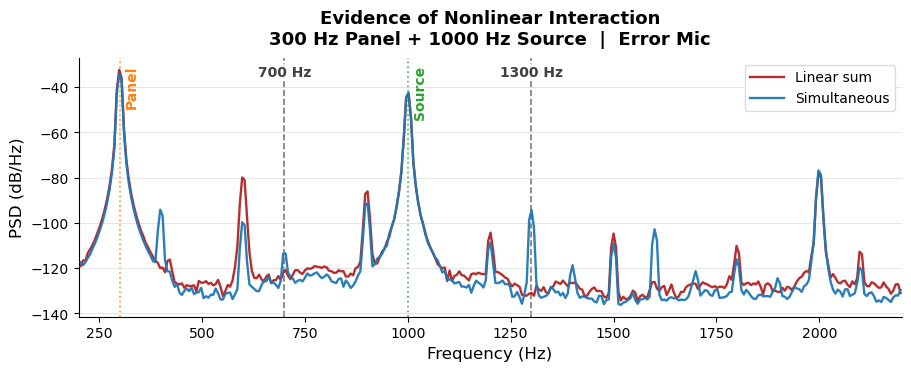

In [19]:
fig, ax = plot_spectra(
    data,
    panel_freq=300,
    source_freq=1000,
    panel_amp=0.5,
    geom='direct',

    show_source=False,
    show_panel=False,
    show_sum=True,
    show_dual=True,
    sum_mode = 'waveform',

    show_fundamentals=True,
    error_mic=True,
    freq_min=200,
    freq_max=2200
)

In [20]:

fig.savefig(
    "nonlinear_interaction.svg",
    format="svg",
    bbox_inches="tight"
)

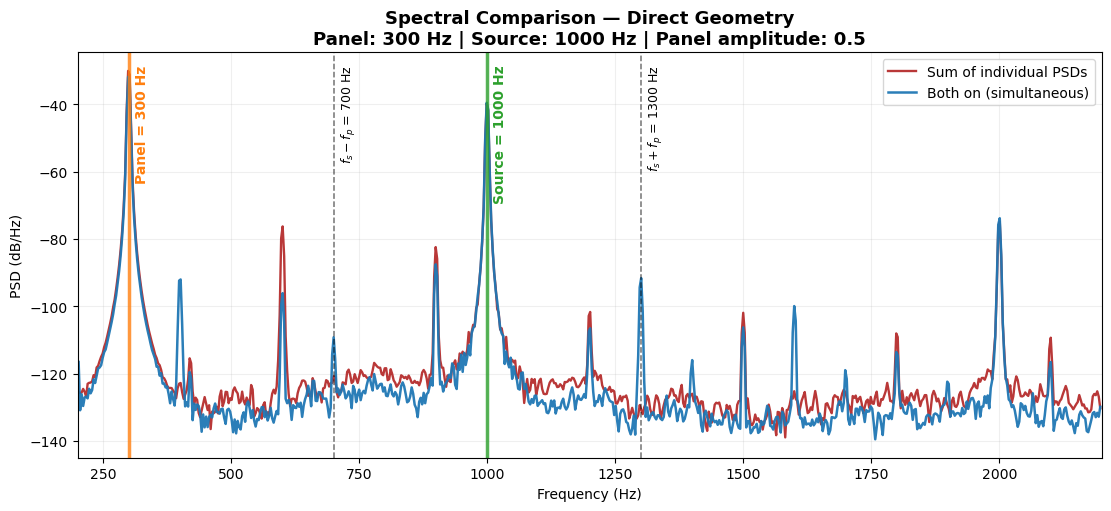

(<Figure size 1100x500 with 1 Axes>,
 <Axes: title={'center': 'Spectral Comparison — Direct Geometry\nPanel: 300 Hz | Source: 1000 Hz | Panel amplitude: 0.5'}, xlabel='Frequency (Hz)', ylabel='PSD (dB/Hz)'>)

In [ ]:
plot_spectra(
    data,
    panel_freq=300,
    source_freq=1000,
    panel_amp=0.5,
    geom='direct',

    show_source=False,
    show_panel=False,
    show_sum=True,
    show_dual=True,

    show_fundamentals=True,

    freq_min=200,
    freq_max=2200
)

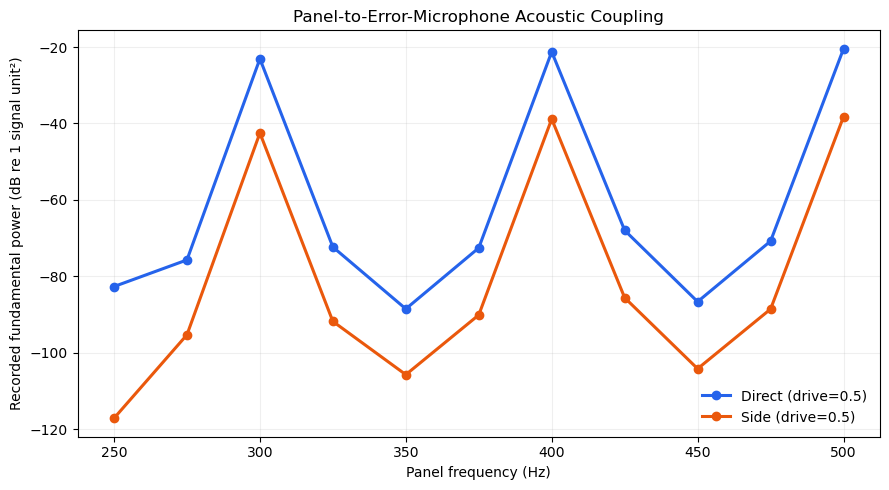

In [32]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Choose a panel amplitude present in both datasets
A_PLOT = 0.5

colors = {"direct": "#2563EB", "side": "#EA580C"}

def fundamental_level(x, fs, freq, bandwidth=5):
    """Integrated power around a sinusoidal fundamental, in dB."""
    f, p = welch(
        x, fs=fs,
        nperseg=min(len(x), 16384),
        noverlap=min(len(x), 16384) // 2
    )
    band = np.abs(f - freq) <= bandwidth
    power = np.sum(p[band]) * (f[1] - f[0])
    return 10 * np.log10(max(power, 1e-30))

fig, ax = plt.subplots(figsize=(9, 5))

levels = {}

for geom, d in data.items():
    freqs = np.asarray(d["panel_freqs"])
    amps = np.asarray(d["panel_amps"])

    ak_plot = np.argmin(np.abs(amps - A_PLOT))
    actual_amp = amps[ak_plot]

    fs = float(d["fs"])
    values = np.array([
        fundamental_level(
            d["error_panel"][i, ak_plot],
            fs,
            freq
        )
        for i, freq in enumerate(freqs)
    ])

    levels[geom] = (freqs, values)

    ax.plot(
        freqs, values,
        "o-", linewidth=2.2,
        markersize=6,
        color=colors[geom],
        label=f"{geom.capitalize()} (drive={actual_amp:g})"
    )

ax.set(
    xlabel="Panel frequency (Hz)",
    ylabel="Recorded fundamental power (dB re 1 signal unit²)",
    title="Panel-to-Error-Microphone Acoustic Coupling"
)

ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# Optional exports
# fig.savefig("panel_coupling.png", dpi=300, bbox_inches="tight")
# fig.savefig("panel_coupling.pdf", bbox_inches="tight")


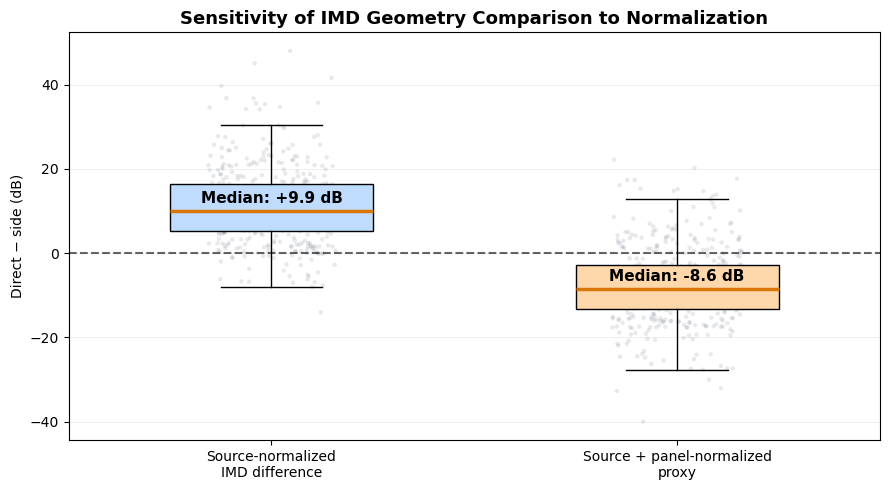

Matched products: 419
Original median: +9.94 dB
Proxy median:    -8.56 dB


In [33]:

# Build fundamental-level lookup tables for each geometry
fundamentals = {}

for geom, d in data.items():
    fs = float(d["fs"])

    panel_levels = {}
    for i, fp in enumerate(d["panel_freqs"]):
        for k, amp in enumerate(d["panel_amps"]):
            panel_levels[(float(fp), float(amp))] = fundamental_level(
                d["error_panel"][i, k], fs, fp
            )

    fundamentals[geom] = panel_levels

# Start with matched IMD products
sub = comparison.copy()

# Adjust these filters if your comparison DataFrame uses
# different column names.
sub = sub[
    (sub["channel"] == "error")
    & (sub["clean"])
    & (sub["clearance_dB_direct"] >= 10)
    & (sub["clearance_dB_side"] >= 10)
].copy()

sub = sub[
    np.isfinite(sub["positive_excess_dBc_direct"])
    & np.isfinite(sub["positive_excess_dBc_side"])
]

# Original difference: each IMD product relative to its
# geometry's source fundamental
sub["source_normalized"] = (
    sub["positive_excess_dBc_direct"]
    - sub["positive_excess_dBc_side"]
)

# Difference in panel fundamental level between geometries
def panel_coupling_difference(row):
    key = (float(row["panel_freq"]), float(row["panel_amp"]))

    return (
        fundamentals["direct"][key]
        - fundamentals["side"][key]
    )

sub["panel_coupling_difference"] = sub.apply(
    panel_coupling_difference, axis=1
)

# Bilinear-inspired proxy:
# subtract the panel fundamental level difference
sub["panel_normalized_proxy"] = (
    sub["source_normalized"]
    - sub["panel_coupling_difference"]
)

values = [
    sub["source_normalized"].to_numpy(),
    sub["panel_normalized_proxy"].to_numpy()
]

fig, ax = plt.subplots(figsize=(9, 5))

bp = ax.boxplot(
    values,
    positions=[1, 2],
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="#D97706", linewidth=2.5)
)

for box, color in zip(bp["boxes"], ["#BFDBFE", "#FED7AA"]):
    box.set_facecolor(color)

rng = np.random.default_rng(42)

for i, y in enumerate(values, start=1):
    ax.scatter(
        i + rng.uniform(-0.16, 0.16, len(y)),
        y,
        s=10, alpha=0.13,
        color="#475569",
        edgecolors="none"
    )

    median = np.median(y)
    ax.text(
        i, median + 2,
        f"Median: {median:+.1f} dB",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.axhline(0, color="black", linestyle="--", alpha=0.6)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    "Source-normalized\nIMD difference",
    "Source + panel-normalized\nproxy"
])

ax.set_ylabel("Direct − side (dB)")
ax.set_title(
    "Sensitivity of IMD Geometry Comparison to Normalization",
    fontsize=13, fontweight="bold"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print(f"Matched products: {len(sub)}")
print(f"Original median: {np.median(values[0]):+.2f} dB")
print(f"Proxy median:    {np.median(values[1]):+.2f} dB")

# Optional exports
# fig.savefig("imd_normalization.png", dpi=300, bbox_inches="tight")
# fig.savefig("imd_normalization.pdf", bbox_inches="tight")


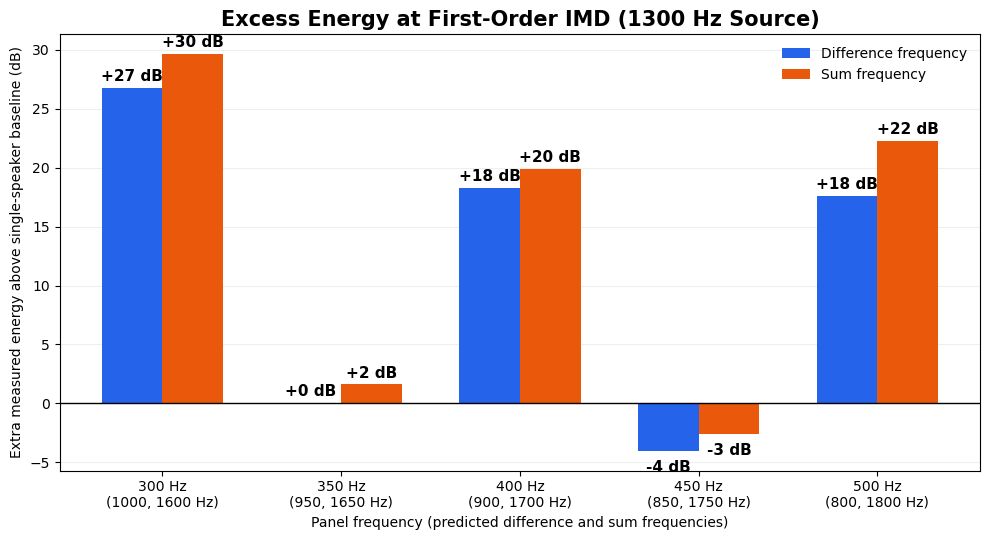

In [41]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

d = data["direct"]
fs = float(d["fs"])

panel_freqs = np.asarray(d["panel_freqs"], dtype=float)
source_freqs = np.asarray(d["source_freqs"], dtype=float)
panel_amps = np.asarray(d["panel_amps"], dtype=float)

source_target = 1300
panel_amp_target = 0.5

sj = np.argmin(abs(source_freqs - source_target))
ak = np.argmin(abs(panel_amps - panel_amp_target))

source_freq = source_freqs[sj]

def get_psd(x):
    n = min(16384, len(x))
    return welch(
        x, fs=fs,
        nperseg=n,
        noverlap=n // 2,
        window="hann",
        scaling="density"
    )

def band_power(f, p, target, width=8):
    mask = abs(f - target) <= width
    return np.sum(p[mask]) * (f[1] - f[0])

def level_difference(pi, target):
    f, pb = get_psd(d["error_both"][pi, sj, ak])
    _, pp = get_psd(d["error_panel"][pi, ak])
    _, ps = get_psd(d["error_source"][sj])

    both = band_power(f, pb, target)
    baseline = (
        band_power(f, pp, target)
        + band_power(f, ps, target)
    )

    return 10 * np.log10(
        max(both, 1e-30) / max(baseline, 1e-30)
    )

# Focus on the three strongest panel excitations
selected = [300, 350, 400, 450, 500]

lower = []
upper = []

for fp in selected:
    pi = np.argmin(abs(panel_freqs - fp))

    lower.append(
        level_difference(pi, source_freq - fp)
    )
    upper.append(
        level_difference(pi, source_freq + fp)
    )

x = np.arange(len(selected))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 5.5))

bars1 = ax.bar(
    x - width/2, lower, width,
    color="#2563EB",
    label="Difference frequency"
)

bars2 = ax.bar(
    x + width/2, upper, width,
    color="#EA580C",
    label="Sum frequency"
)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:+.0f} dB",
            (bar.get_x() + bar.get_width()/2, height),
            xytext=(0, 5 if height >= 0 else -15),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

ax.axhline(0, color="black", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels([
    f"{fp} Hz\n"
    f"({source_freq-fp:.0f}, {source_freq+fp:.0f} Hz)"
    for fp in selected
])

ax.set_xlabel(
    "Panel frequency (predicted difference and sum frequencies)"
)

ax.set_ylabel(
    "Extra measured energy above single-speaker baseline (dB)"
)

ax.set_title(
    "Excess Energy at First-Order IMD (1300 Hz Source)",
    fontsize=15, fontweight="bold"
)

ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

# fig.savefig("imd_summary.png", dpi=300, bbox_inches="tight")


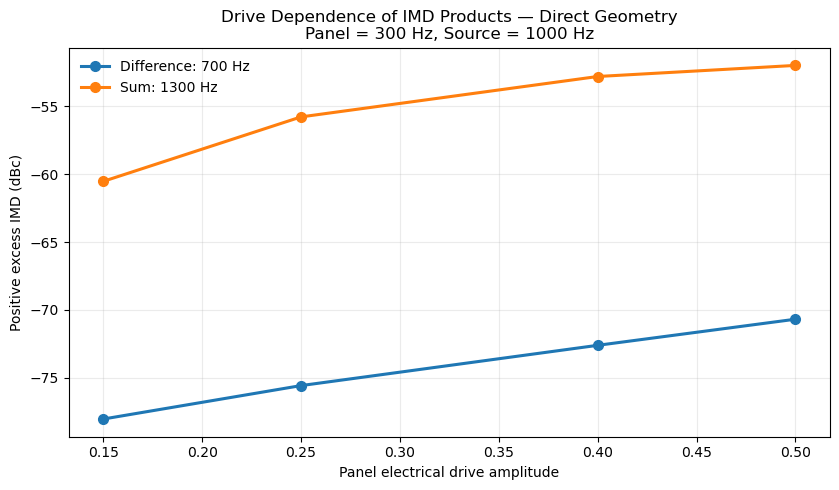

In [35]:

d = data["direct"]

fs = float(d["fs"])
panel_freqs = np.asarray(d["panel_freqs"], dtype=float)
source_freqs = np.asarray(d["source_freqs"], dtype=float)
panel_amps = np.asarray(d["panel_amps"], dtype=float)

pi = np.argmin(np.abs(panel_freqs - 300))
sj = np.argmin(np.abs(source_freqs - 1000))

fp = panel_freqs[pi]
fsrc = source_freqs[sj]

def band_power(f, p, target, half_width=8):
    mask = np.abs(f - target) <= half_width
    return np.sum(p[mask]) * (f[1] - f[0])

# Source-only fundamental reference
f, ps = get_psd(d["error_source"][sj])
source_power = band_power(f, ps, fsrc)

products = {
    "Difference": abs(fsrc - fp),
    "Sum": fsrc + fp
}

fig, ax = plt.subplots(figsize=(8.5, 5))

for label, target in products.items():
    levels = []

    for ak, amp in enumerate(panel_amps):
        f, pb = get_psd(d["error_both"][pi, sj, ak])
        _, pp = get_psd(d["error_panel"][pi, ak])
        _, ps = get_psd(d["error_source"][sj])

        p_both = band_power(f, pb, target)
        p_panel = band_power(f, pp, target)
        p_source = band_power(f, ps, target)

        excess = max(p_both - p_panel - p_source, 0)

        if excess > 0 and source_power > 0:
            level = 10 * np.log10(excess / source_power)
        else:
            level = np.nan

        levels.append(level)

    ax.plot(
        panel_amps,
        levels,
        "o-",
        lw=2.2,
        markersize=7,
        label=f"{label}: {target:g} Hz"
    )

ax.set(
    xlabel="Panel electrical drive amplitude",
    ylabel="Positive excess IMD (dBc)",
    title=(
        f"Drive Dependence of IMD Products — Direct Geometry\n"
        f"Panel = {fp:g} Hz, Source = {fsrc:g} Hz"
    )
)

ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


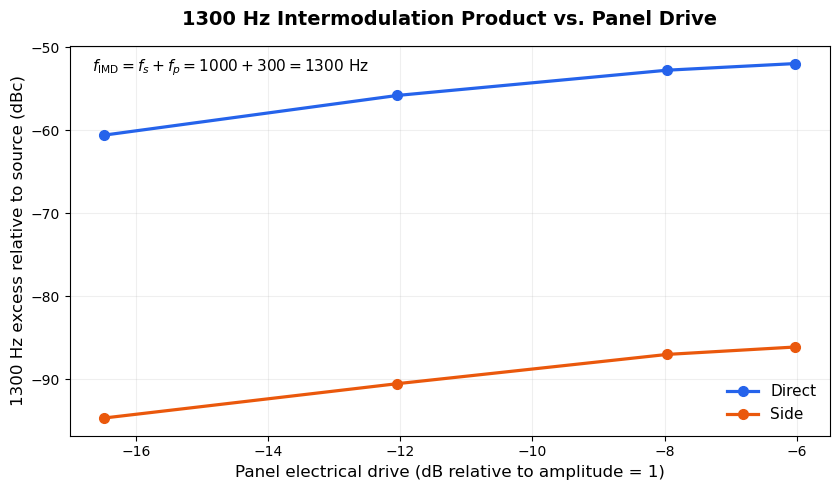

In [29]:

# 300 Hz panel + 1000 Hz source -> 1300 Hz IMD
fp = 300
fs_source = 1000
f_imd = 1300

sub = imd[
    (imd.channel == "error")
    & (imd.panel_freq == fp)
    & (imd.source_freq == fs_source)
    & (imd.m == 1)
    & (imd.n == 1)
    & (imd.sign == 1)
    & np.isclose(imd.freq, f_imd, atol=2)
].copy()

sub["drive_dB"] = 20 * np.log10(sub.panel_amp)

fig, ax = plt.subplots(figsize=(8.5, 5))

colors = {
    "direct": "#2563EB",
    "side": "#EA580C"
}

for geom in ["direct", "side"]:
    g = sub[
        (sub.geometry == geom)
        & np.isfinite(sub.positive_excess_dBc)
    ].sort_values("drive_dB")

    ax.plot(
        g.drive_dB,
        g.positive_excess_dBc,
        "o-",
        color=colors[geom],
        linewidth=2.3,
        markersize=7,
        label=geom.capitalize()
    )

ax.set_xlabel(
    "Panel electrical drive (dB relative to amplitude = 1)",
    fontsize=12
)
ax.set_ylabel(
    "1300 Hz excess relative to source (dBc)",
    fontsize=12
)
ax.set_title(
    "1300 Hz Intermodulation Product vs. Panel Drive",
    fontsize=14, fontweight="bold", pad=15
)

ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=11)

# Label the physical interaction
ax.text(
    0.03, 0.97,
    r"$f_{\mathrm{IMD}} = f_s + f_p = 1000 + 300 = 1300$ Hz",
    transform=ax.transAxes,
    ha="left", va="top",
    fontsize=11
)

fig.tight_layout()
plt.show()

# Optional exports
# fig.savefig("imd_amplitude.png", dpi=300, bbox_inches="tight")
# fig.savefig("imd_amplitude.pdf", bbox_inches="tight")


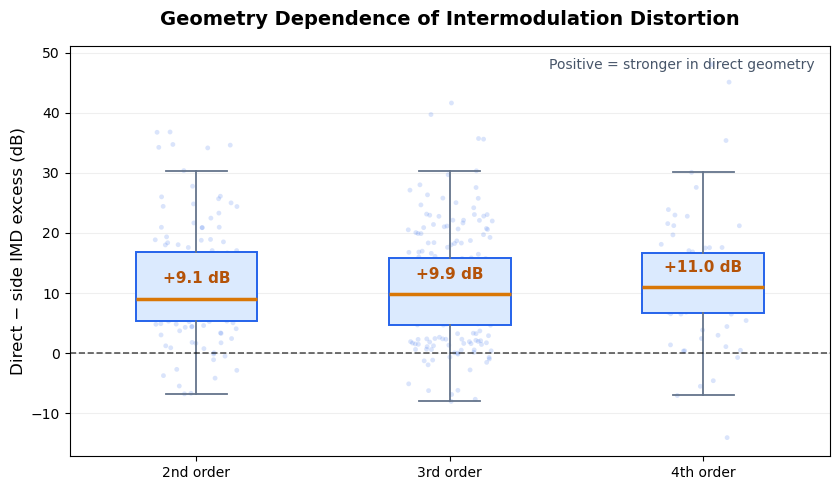

In [30]:
# Matched, clean, detectable IMD products
sub = comparison[
    (comparison.channel == "error")
    & comparison.clean
    & (comparison.clearance_dB_direct >= 10)
    & (comparison.clearance_dB_side >= 10)
    & np.isfinite(comparison.positive_excess_dBc_direct)
    & np.isfinite(comparison.positive_excess_dBc_side)
].copy()

sub["difference_dB"] = (
    sub["positive_excess_dBc_direct"]
    - sub["positive_excess_dBc_side"]
)

orders = [2, 3, 4]
values = [
    sub.loc[sub.order == order, "difference_dB"].to_numpy()
    for order in orders
]

fig, ax = plt.subplots(figsize=(8.5, 5))

bp = ax.boxplot(
    values,
    positions=orders,
    widths=0.48,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="#D97706", linewidth=2.5),
    boxprops=dict(edgecolor="#2563EB", linewidth=1.4),
    whiskerprops=dict(color="#64748B", linewidth=1.3),
    capprops=dict(color="#64748B", linewidth=1.3)
)

for box in bp["boxes"]:
    box.set_facecolor("#DBEAFE")

# Individual matched products (jittered for visibility)
rng = np.random.default_rng(42)

for order, y in zip(orders, values):
    x = order + rng.uniform(-0.17, 0.17, len(y))
    ax.scatter(
        x, y,
        s=12, alpha=0.17,
        color="#2563EB",
        edgecolors="none"
    )

    median = np.median(y)
    ax.text(
        order, median + 2.5,
        f"{median:+.1f} dB",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#B45309"
    )

ax.axhline(
    0, color="black",
    linestyle="--", linewidth=1.2,
    alpha=0.65
)

ax.set_xticks(orders)
ax.set_xticklabels([
    "2nd order",
    "3rd order",
    "4th order"
])

ax.set_ylabel("Direct − side IMD excess (dB)", fontsize=12)
ax.set_title(
    "Geometry Dependence of Intermodulation Distortion",
    fontsize=14, fontweight="bold", pad=15
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Explain the direction of the comparison
ax.text(
    0.98, 0.97,
    "Positive = stronger in direct geometry",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=10, color="#475569"
)

fig.tight_layout()
plt.show()

# Optional exports
# fig.savefig("imd_geometry.png", dpi=300, bbox_inches="tight")
# fig.savefig("imd_geometry.pdf", bbox_inches="tight")


## 13. Optional spectrograms and stationarity check

Inspect whether products are steady throughout the retained second. This helps identify transients, drifting tones, or acquisition artifacts.

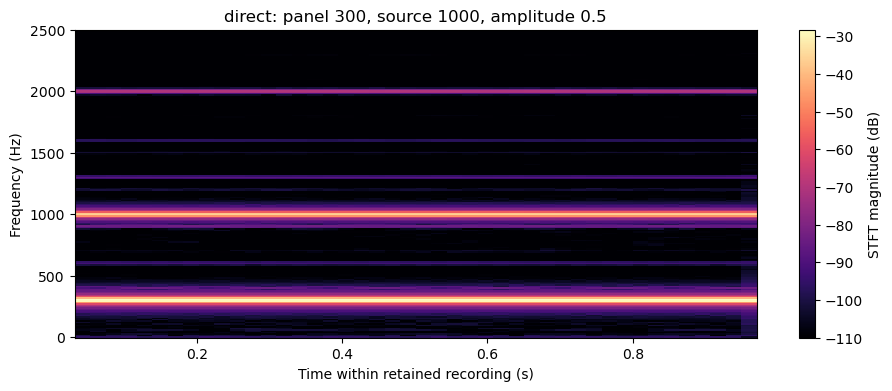

In [14]:
FIG_GEOMETRY='direct'
FIG_PANEL=300;FIG_SOURCE=1000;FIG_AMP=0.5
fi=idx_exact(panel_freqs,FIG_PANEL);fj=idx_exact(source_freqs,FIG_SOURCE);fk=idx_exact(panel_amps,FIG_AMP)
x=data[FIG_GEOMETRY]['error_both'][fi,fj,fk]
f,t,z=signal.stft(x,fs=fs,nperseg=8192,noverlap=6144,boundary=None)
sel=f<=2500
fig,ax=plt.subplots(figsize=(11,4))
mesh=ax.pcolormesh(t,f[sel],db20(np.abs(z[sel])),shading='auto',cmap='magma',vmin=-110)
ax.set(xlabel='Time within retained recording (s)',ylabel='Frequency (Hz)',
       title=f'{FIG_GEOMETRY}: panel {FIG_PANEL}, source {FIG_SOURCE}, amplitude {FIG_AMP}')
fig.colorbar(mesh,ax=ax,label='STFT magnitude (dB)');plt.show()

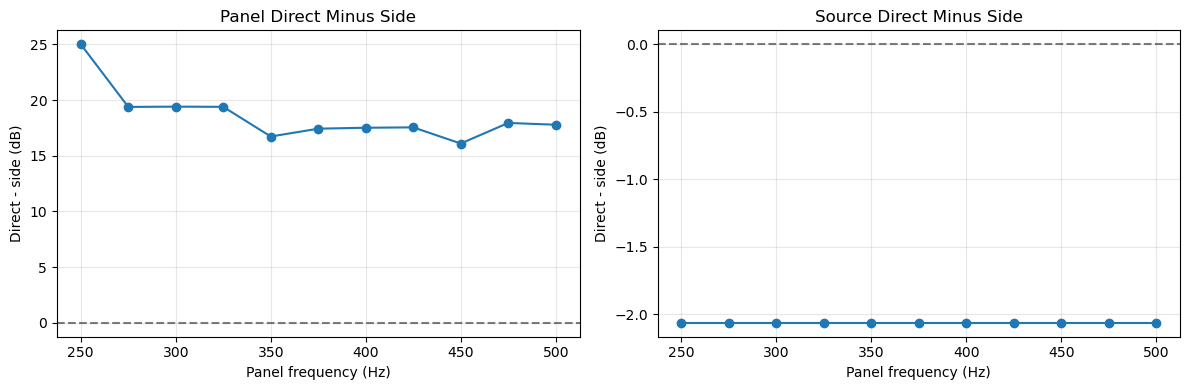

In [15]:

# Acoustic fundamental levels for each geometry and panel amplitude.
# Use integrated PSD power, not a single FFT-bin height.

level_rows = []

for geom, d in data.items():
    for i, fp in enumerate(panel_freqs):
        for j, sf in enumerate(source_freqs):
            for k, amp in enumerate(panel_amps):
                for ch in ["error", "ref"]:
                    _, pp = psd(d[f"{ch}_panel"][i, k])
                    f, ps = psd(d[f"{ch}_source"][j])

                    panel_power = band_power(f, pp, fp)
                    source_power = band_power(f, ps, sf)

                    level_rows.append({
                        "geometry": geom,
                        "channel": ch,
                        "panel_freq": float(fp),
                        "source_freq": float(sf),
                        "panel_amp": float(amp),
                        "panel_power": panel_power,
                        "source_power": source_power,
                        "panel_dBFS": db10(panel_power),
                        "source_dBFS": db10(source_power),
                    })

levels = pd.DataFrame(level_rows)

# Direct-minus-side fundamental levels.
level_compare = levels.pivot(
    index=["channel", "panel_freq", "source_freq", "panel_amp"],
    columns="geometry",
    values=["panel_dBFS", "source_dBFS"]
)

level_compare.columns = [
    f"{metric}_{geom}" for metric, geom in level_compare.columns
]
level_compare = level_compare.reset_index()

for name in ["panel", "source"]:
    level_compare[f"{name}_direct_minus_side"] = (
        level_compare[f"{name}_dBFS_direct"]
        - level_compare[f"{name}_dBFS_side"]
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(
    axes, ["panel_direct_minus_side", "source_direct_minus_side"]
):
    sub = level_compare[level_compare.channel == "error"]
    vals = sub.groupby("panel_freq")[metric].median()
    ax.plot(vals.index, vals.values, "o-")
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set(
        xlabel="Panel frequency (Hz)",
        ylabel="Direct - side (dB)",
        title=metric.replace("_", " ").title()
    )
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Matched products: 419
count    419.000000
mean      -7.246837
std        9.140178
min      -36.484183
25%      -13.172533
50%       -8.399972
75%       -2.415439
max       22.203798
Name: direct_minus_side, dtype: float64


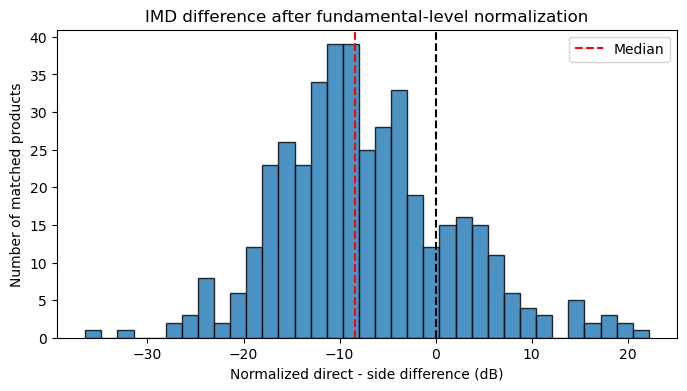

In [16]:

# Normalize clean IMD candidates by measured fundamental levels.

norm = imd.merge(
    levels,
    on=[
        "geometry", "channel",
        "panel_freq", "source_freq", "panel_amp"
    ],
    validate="many_to_one"
)

norm = norm[
    (norm.channel == "error")
    & norm.clean
    & (norm.clearance_dB >= 10)
    & np.isfinite(norm.positive_excess_dBc)
].copy()

# Convert dBc back to absolute level before normalizing.
norm["excess_dBFS"] = (
    norm["positive_excess_dBc"] + norm["source_dBFS"]
)

norm["bilinear_normalized_dB"] = (
    norm["excess_dBFS"]
    - norm["panel_dBFS"]
    - norm["source_dBFS"]
)

# Compare identical IMD products across geometries.
keys = [
    "panel_freq", "source_freq", "panel_amp",
    "freq", "m", "n", "sign"
]

paired_norm = norm.pivot_table(
    index=keys,
    columns="geometry",
    values="bilinear_normalized_dB"
).dropna()

paired_norm["direct_minus_side"] = (
    paired_norm["direct"] - paired_norm["side"]
)

print("Matched products:", len(paired_norm))
print(paired_norm["direct_minus_side"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    paired_norm["direct_minus_side"],
    bins=35,
    edgecolor="black",
    alpha=0.8
)
ax.axvline(0, color="black", linestyle="--")
ax.axvline(
    paired_norm["direct_minus_side"].median(),
    color="red",
    linestyle="--",
    label="Median"
)
ax.set(
    xlabel="Normalized direct - side difference (dB)",
    ylabel="Number of matched products",
    title="IMD difference after fundamental-level normalization"
)
ax.legend()
plt.show()


Matched slope pairs: 103


geometry,direct,side,difference
count,103.000000,103.000000,103.000000
mean,0.792794,0.344699,0.448096
std,0.719742,0.956117,1.095552
min,-1.416814,-1.779491,-2.412564
25%,0.599749,-0.445952,-0.197154
50%,0.859935,0.462012,0.244095
75%,1.231397,1.012939,1.054922
max,2.537820,2.368584,2.945747


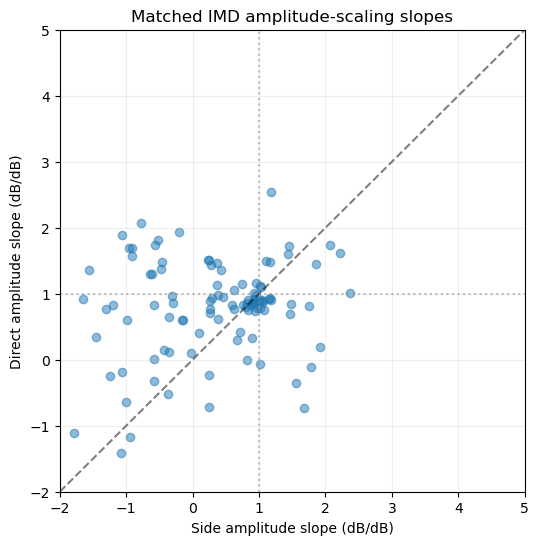

count  median   mean
geometry m n                      
direct   1 1     37   0.854  0.836
           2     24   0.880  0.878
           3      5  -1.238 -1.324
         2 1     45   1.373  1.007
           2      9   0.807  0.663
         3 1      9   0.096  0.244
side     1 1     37   0.719  0.623
           2     30   0.859  0.550
           3      3  -0.958 -1.133
         2 1     37  -0.150  0.131
           2     19  -0.509 -0.319
         3 1     15  -0.056 -0.080

In [17]:

# Compare fitted amplitude slopes for matching IMD products.

slope_keys = [
    "panel_freq", "source_freq", "freq",
    "m", "n", "sign"
]

slope_pairs = slopes.pivot_table(
    index=slope_keys,
    columns="geometry",
    values="slope_db_per_db"
).dropna()

slope_pairs["difference"] = (
    slope_pairs["direct"] - slope_pairs["side"]
)

print("Matched slope pairs:", len(slope_pairs))
display(slope_pairs.describe())

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    slope_pairs["side"],
    slope_pairs["direct"],
    alpha=0.5
)

ax.plot([-2, 5], [-2, 5], "k--", alpha=0.5)
ax.axhline(1, color="gray", linestyle=":", alpha=0.5)
ax.axvline(1, color="gray", linestyle=":", alpha=0.5)

ax.set(
    xlabel="Side amplitude slope (dB/dB)",
    ylabel="Direct amplitude slope (dB/dB)",
    title="Matched IMD amplitude-scaling slopes",
    xlim=(-2, 5),
    ylim=(-2, 5)
)
ax.grid(alpha=0.2)
plt.show()

# Median slope by IMD order.
display(
    slopes.groupby(["geometry", "m", "n"])[
        "slope_db_per_db"
    ].agg(["count", "median", "mean"]).round(3)
)


Matched detected products: 419


,count,median,mean,std
order,,,,
2,132,9.09,11.34,9.28
3,217,9.91,10.75,8.85
4,70,11.00,11.92,10.42


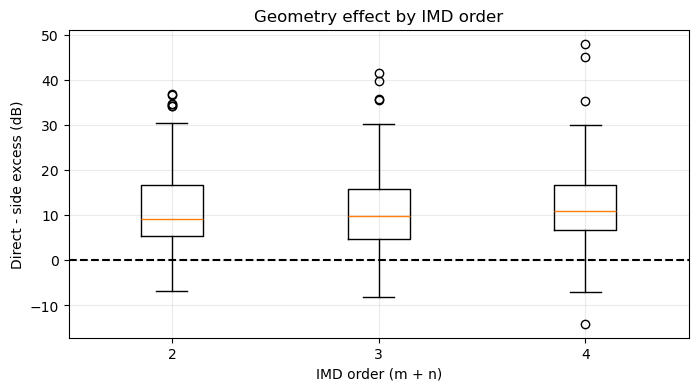

In [18]:

sub = comparison[
    (comparison.channel == "error")
    & comparison.clean
    & (comparison.clearance_dB_direct >= 10)
    & (comparison.clearance_dB_side >= 10)
    & np.isfinite(comparison.positive_excess_dBc_direct)
    & np.isfinite(comparison.positive_excess_dBc_side)
].copy()

sub["difference_dB"] = (
    sub.positive_excess_dBc_direct
    - sub.positive_excess_dBc_side
)

print("Matched detected products:", len(sub))

display(
    sub.groupby("order")["difference_dB"].agg(
        ["count", "median", "mean", "std"]
    ).round(2)
)

fig, ax = plt.subplots(figsize=(8, 4))

orders = sorted(sub.order.unique())
values = [
    sub.loc[sub.order == order, "difference_dB"].values
    for order in orders
]

ax.boxplot(values, tick_labels=[str(x) for x in orders])
ax.axhline(0, color="black", linestyle="--")
ax.set(
    xlabel="IMD order (m + n)",
    ylabel="Direct - side excess (dB)",
    title="Geometry effect by IMD order"
)
ax.grid(alpha=0.25)
plt.show()


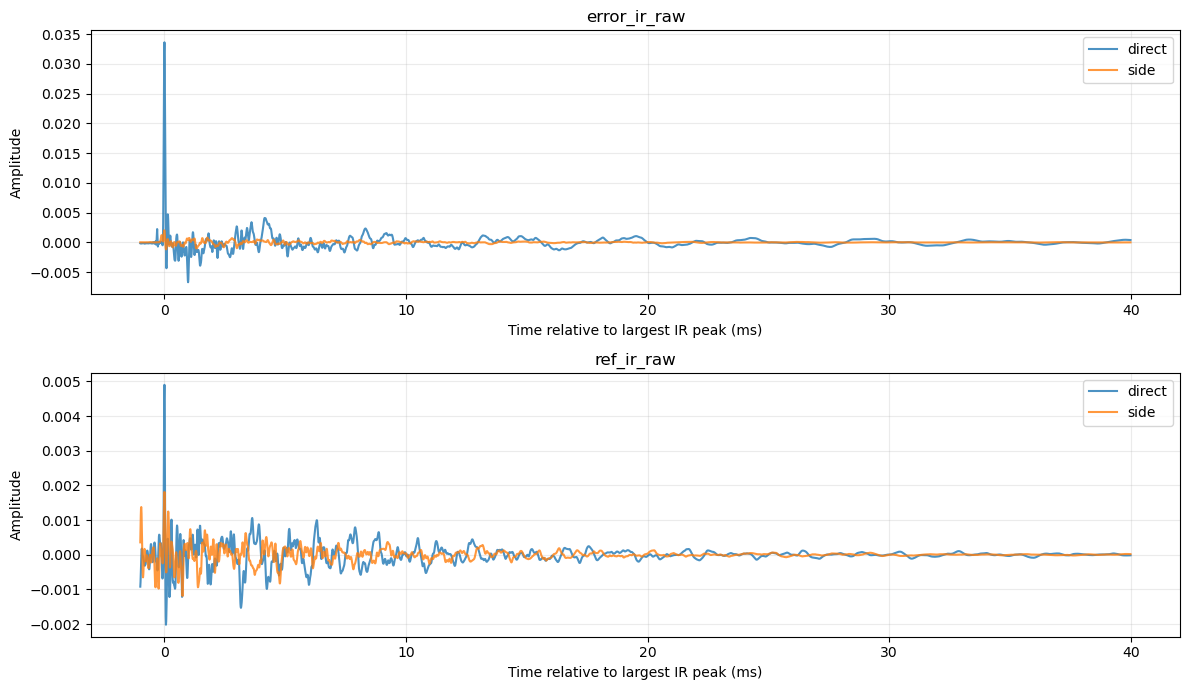

In [19]:

# Plot short windows around the dominant IR arrivals.
# This is a diagnostic view, not a causal IR alignment.

PRE_MS = 1.0
POST_MS = 40.0

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, key in zip(
    axes, ["error_ir_raw", "ref_ir_raw"]
):
    for geom, d in data.items():
        h = np.asarray(d[key]).squeeze()
        peak = np.argmax(np.abs(h))

        pre = int(PRE_MS * fs / 1000)
        post = int(POST_MS * fs / 1000)

        start = max(0, peak - pre)
        stop = min(len(h), peak + post)

        window = h[start:stop]
        t = (np.arange(start, stop) - peak) / fs * 1000

        ax.plot(t, window, label=geom, alpha=0.8)

    ax.set(
        xlabel="Time relative to largest IR peak (ms)",
        ylabel="Amplitude",
        title=key
    )
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()
